<a href="https://colab.research.google.com/github/GustavoCCamargo/Ci-ncia_de_Dados_Brasileir-o_S-rie_A/blob/main/Bases_Trabalho_Ci%C3%AAncia_de_Dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BASE DE DADOS DO BRASILEIRÃO SÉRIE A 2003-2024

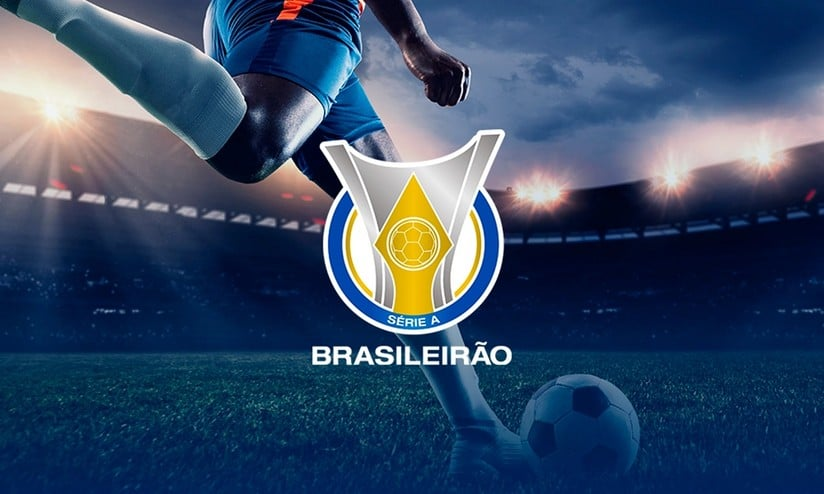

### INTRODUÇÃO

Base de dados retirada do Kaggle, sobre dados do brasileirão série A de 2003 a 2024.
link base:  https://basedosdados.org/dataset/c861330e-bca2-474d-9073-bc70744a1b23?table=18835b0d-233e-4857-b454-1fa34a81b4fa&utm_term=base%20de%20dados%20futebol&utm_campaign=Conjuntos+de+Dados+-+BD+Pro&utm_source=adwords&utm_medium=ppc&hsa_acc=9488864076&hsa_cam=20477806005&hsa_grp=159509357264&hsa_ad=670893357725&hsa_src=g&hsa_tgt=kwd-759358379019&hsa_kw=base%20de%20dados%20futebol&hsa_mt=b&hsa_net=adwords&hsa_ver=3&gad_source=1&gad_campaignid=20477806005&gbraid=0AAAAApsIj8zq_PAhDjG9s2Db2wspUgFp_&gclid=CjwKCAjwg7PDBhBxEiwAf1CVu0TkOFLfw6y0GEoWtIFeKnmGcA17taa4a6QTLMLSZZ_InEyULS73zxoCt2AQAvD_BwE


## OBJETIVOS

- Limpeza dos Dados
- Ánalise Explorátoria (Extração de informações)
- Aplicação de Métricas de Avaliação

# BIBLIOTECAS E EXPORTAÇÃO DA BASE

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm
import seaborn as sns
import os
from google.colab import drive
import math


In [ ]:
# monta a base no google drive
drive.mount('drive')
meuDrive = os.path.join('drive', 'My Drive')

Drive already mounted at drive; to attempt to forcibly remount, call drive.mount("drive", force_remount=True).


## Exportação da Base

In [ ]:
# Ajuste para o seu caminho no drive!!!
database_path = os.path.join(meuDrive, 'BasesTrabalho')

# Nome do arquivo CSV dentro do dataset
file_path = os.path.join(database_path, 'df_fut.csv')

df_fut = pd.read_csv(file_path)
df_fut

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante,log_publico,log_publico_max,gols_partida
0,2018,2018-10-06,28,Arena da Baixada,Raphael Claus,11443,42372,Atlético-PR,América-MG,Tiago Nunes,...,0,1,3,4,3,4,1,9.345221,10.654267,4
1,2018,2018-10-02,27,Estádio Durival Britto e Silva,Flavio Rodrigues de Souza,3894,20083,Paraná,Vasco da Gama,Claudinei Oliveira,...,4,2,3,5,3,10,7,8.267449,9.907679,2
2,2018,2018-08-23,20,Estádio Durival Britto e Silva,Péricles Bassols Pegado Cortez,8561,20083,Paraná,São Paulo,Claudinei Oliveira,...,3,2,3,2,3,9,7,9.055089,9.907679,2
3,2018,2018-11-18,35,Estádio Cícero Pompeu de Toledo,Héber Lopes,14058,67428,São Paulo,Cruzeiro,André Jardine,...,3,4,3,4,0,5,4,9.551018,11.118830,1
4,2018,2018-10-30,31,Estádio Governador Plácido Castelo,Wagner Reway,37394,60326,Ceará SC,Atlético-MG,Lisca,...,4,2,2,6,2,3,7,10.529292,11.007535,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2558,2024,2024-07-07,15,Estádio Jornalista Mário Filho,Rodrigo José Pereira de Lima,54948,78838,Flamengo,Cuiabá-MT,Tite,...,4,2,2,16,9,6,4,10.914161,11.275163,2
2559,2024,2024-07-05,14,Estádio Francisco Stédile,Marcelo de Lima Henrique,20797,30540,Grêmio,Palmeiras,Renato Gaúcho,...,4,1,2,12,16,4,6,9.942612,10.326825,4
2560,2024,2024-06-30,13,Estádio Francisco Stédile,Paulo Cesar Zanovelli,16221,30822,Grêmio,Fluminense,Renato Gaúcho,...,4,1,2,12,10,4,4,9.694124,10.336016,1
2561,2024,2024-06-30,13,Estádio Jornalista Mário Filho,Braulio da Silva Machado,56263,78838,Flamengo,Cruzeiro,Tite,...,4,2,2,16,12,6,5,10.937810,11.275163,3


# *ÁNALISE EXPLORATÓRIA DOS DADOS*

# **Ánalises Iniciais**

## **Público**

In [ ]:
#somar o número de colunas de publico que tem valor  = 0
colunas_publico = ['publico', 'publico_max']
df_fut[colunas_publico].eq(0).sum()

,0
publico,614
publico_max,0


In [ ]:
#Verificando os anos que possuem muitos jogos com público 0
df_fut[df_fut['publico'] == 0][['ano_campeonato']]
df_fut[df_fut['publico'] == 0]['ano_campeonato'].value_counts()

,count
ano_campeonato,
2020,380
2021,218
2023,12
2022,3
2019,1


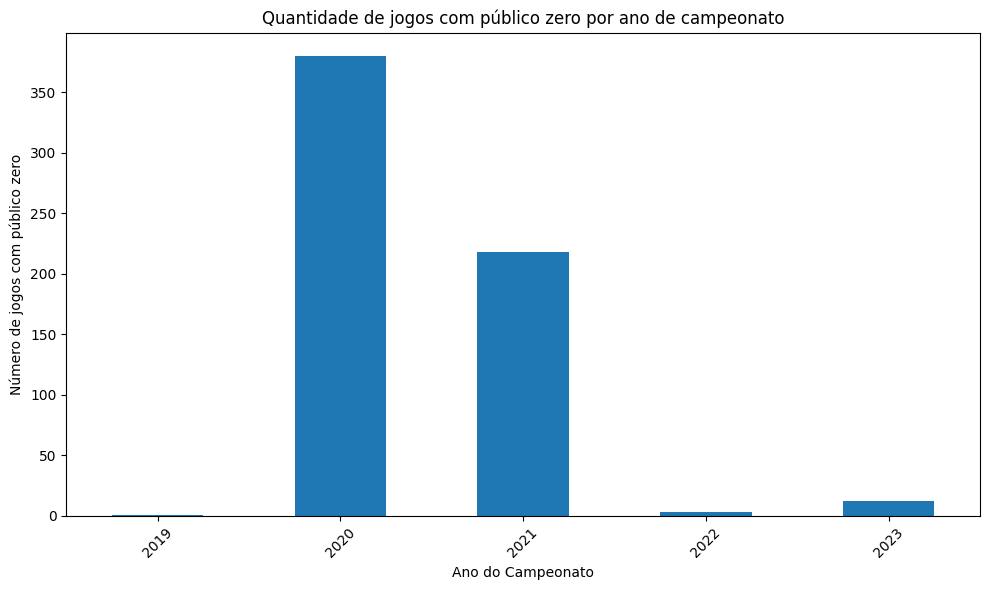

In [ ]:
contagem_anos = df_fut[df_fut['publico'] == 0]['ano_campeonato'].value_counts().sort_index()

# Plota gráfico de barras
plt.figure(figsize=(10,6))
contagem_anos.plot(kind='bar')

plt.title('Quantidade de jogos com público zero por ano de campeonato')
plt.xlabel('Ano do Campeonato')
plt.ylabel('Número de jogos com público zero')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

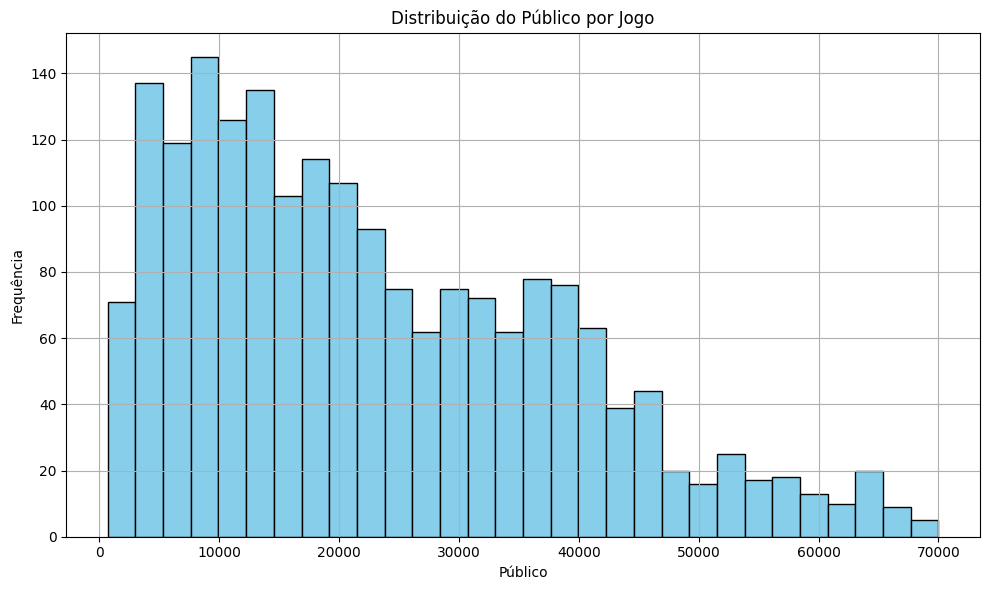

In [ ]:
# Filtra valores válidos de público >0
df_publico = df_fut[df_fut['publico'] >0]



plt.figure(figsize=(10, 6))
plt.hist(df_publico['publico'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribuição do Público por Jogo')
plt.xlabel('Público')
plt.ylabel('Frequência')
plt.grid(True)
plt.tight_layout()
plt.show()

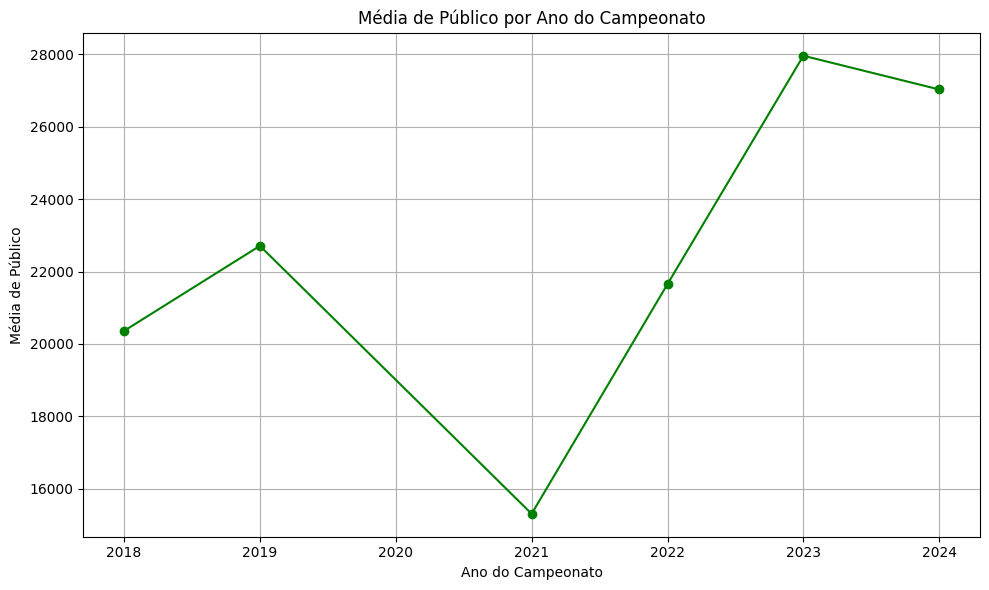

In [ ]:
media_publico_ano = df_publico.groupby('ano_campeonato')['publico'].mean()

# Gráfico de linha
plt.figure(figsize=(10, 6))
plt.plot(media_publico_ano.index, media_publico_ano.values, marker='o', color='green')
plt.title('Média de Público por Ano do Campeonato')
plt.xlabel('Ano do Campeonato')
plt.ylabel('Média de Público')
plt.grid(True)
plt.tight_layout()
plt.show()

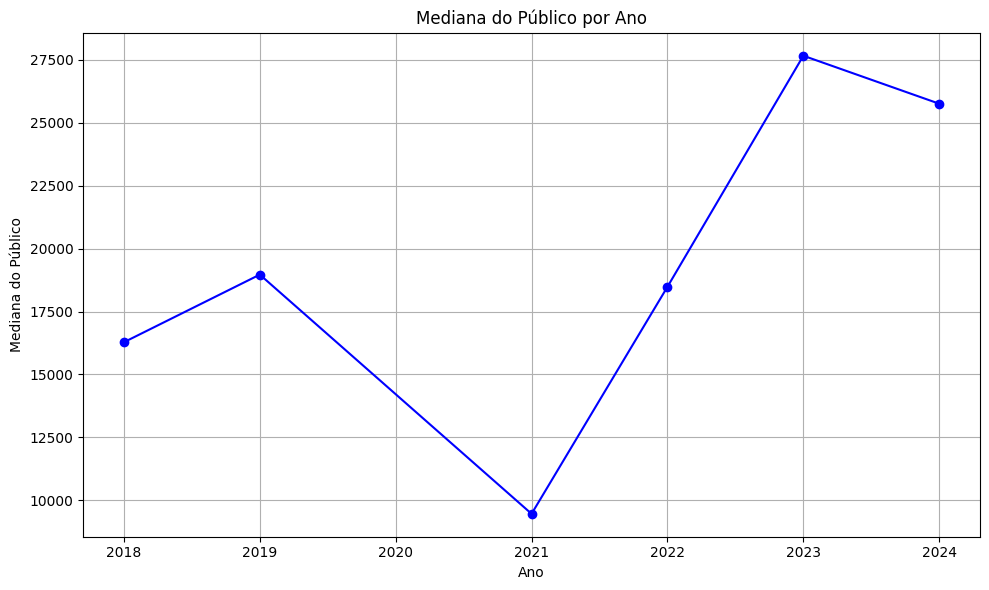

In [ ]:
mediana_publico = df_publico.groupby('ano_campeonato')['publico'].median()

# Gera o gráfico
plt.figure(figsize=(10, 6))
plt.plot(mediana_publico.index, mediana_publico.values, marker='o', color='blue')
plt.title('Mediana do Público por Ano')
plt.xlabel('Ano')
plt.ylabel('Mediana do Público')
plt.grid(True)
plt.tight_layout()
plt.show()

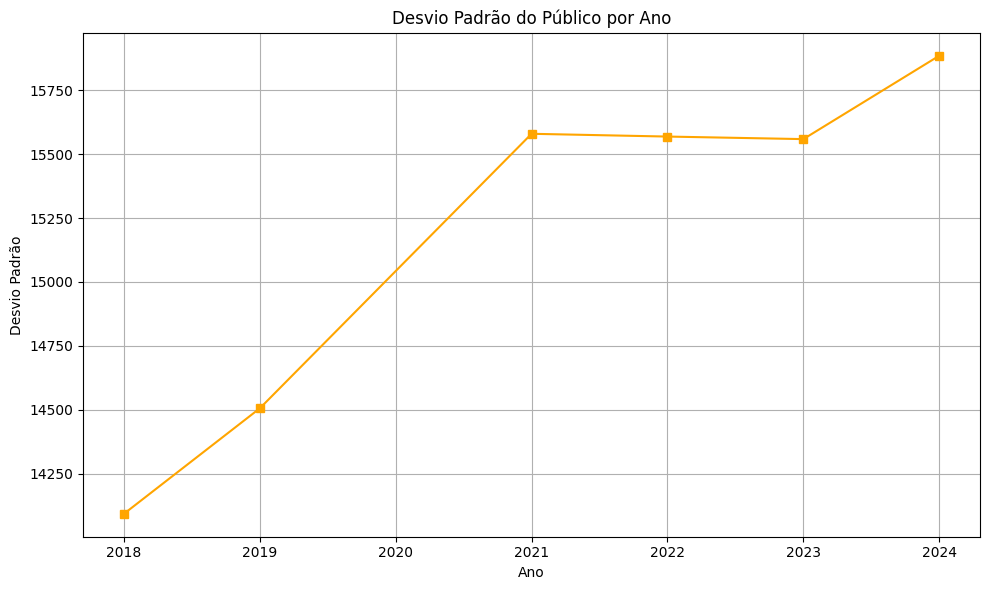

In [ ]:
# Calcula o desvio padrão por ano
desvio_padrao = df_publico.groupby('ano_campeonato')['publico'].std()

# Gera o gráfico
plt.figure(figsize=(10, 6))
plt.plot(desvio_padrao.index, desvio_padrao.values, marker='s', color='orange')
plt.title('Desvio Padrão do Público por Ano')
plt.xlabel('Ano')
plt.ylabel('Desvio Padrão')
plt.grid(True)
plt.tight_layout()
plt.show()

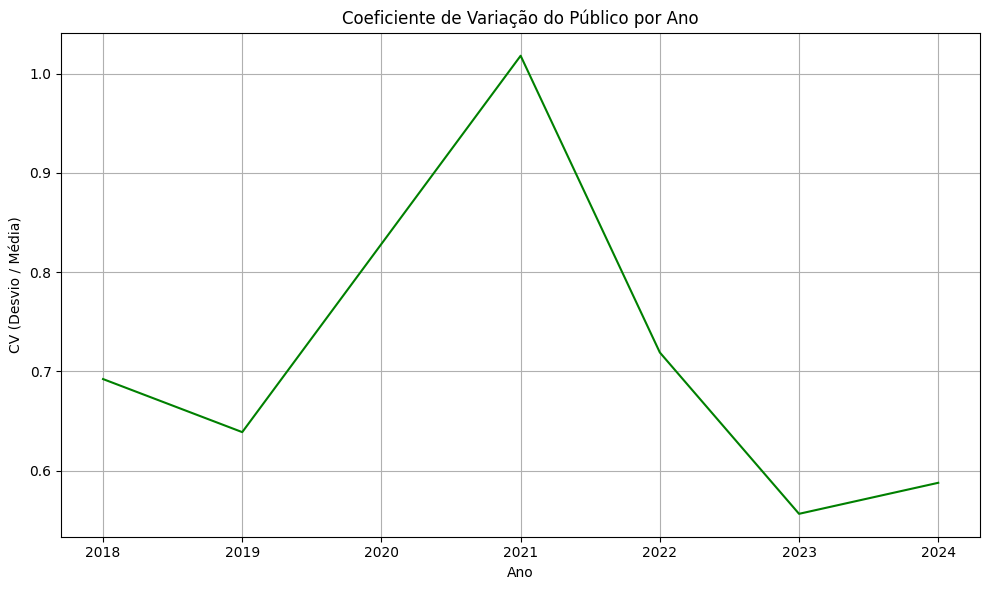

In [ ]:

# CV = desvio padrão / média
cv = desvio_padrao / media_publico_ano

# Gera o gráfico
plt.figure(figsize=(10, 6))
plt.plot(cv.index, cv.values, color='green')
plt.title('Coeficiente de Variação do Público por Ano')
plt.xlabel('Ano')
plt.ylabel('CV (Desvio / Média)')
plt.grid(True)
plt.tight_layout()
plt.show()

## **Jogos**

In [ ]:
jogos_por_ano = df_fut['ano_campeonato'].value_counts().sort_index()

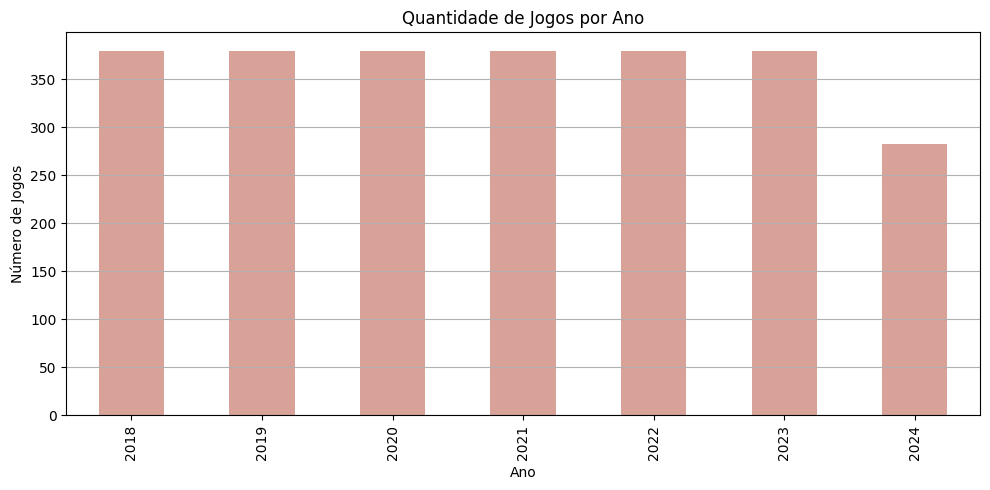

In [ ]:
plt.figure(figsize=(10, 5))
jogos_por_ano.plot(kind='bar', color='#D9A299')

plt.title('Quantidade de Jogos por Ano')
plt.xlabel('Ano')
plt.ylabel('Número de Jogos')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [ ]:
vitoria_mandante = df_fut[(df_fut['gols_mandante'] > df_fut['gols_visitante']) & (df_fut['gols_mandante'] != 0)]
vitoria_visitante = df_fut[(df_fut['gols_mandante'] < df_fut['gols_visitante']) & (df_fut['gols_visitante'] != 0)]

vitoria_mandante_por_ano = vitoria_mandante.groupby('ano_campeonato').size()
vitoria_visitante_por_ano = vitoria_visitante.groupby('ano_campeonato').size()

vitoria_por_ano = vitoria_mandante_por_ano + vitoria_visitante_por_ano
print(vitoria_por_ano)

ano_campeonato
2018    270
2019    282
2020    272
2021    267
2022    272
2023    282
2024    209
dtype: int64


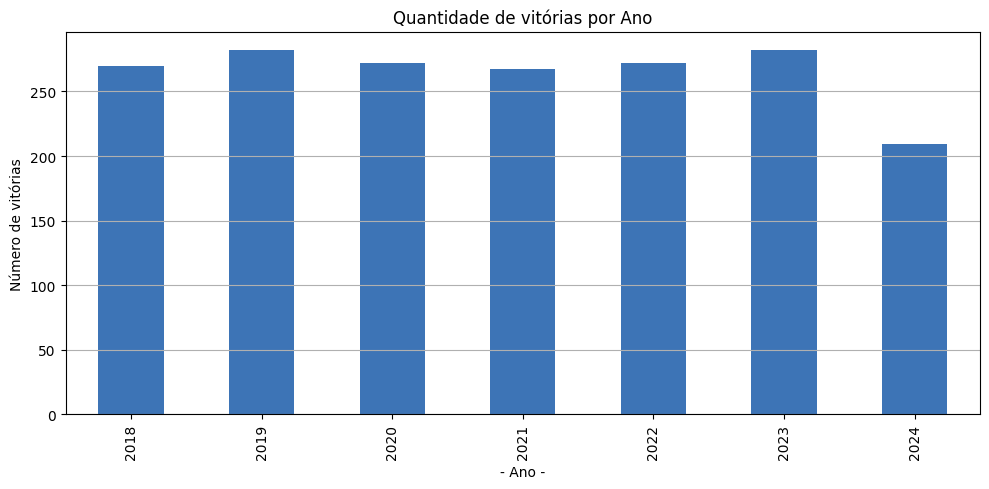

In [ ]:
plt.figure(figsize=(10, 5))
vitoria_por_ano.plot(kind='bar', x='ano_campeonato', y='quantidade_vitoria', color='#3D74B6', legend=False)

plt.title('Quantidade de vitórias por Ano')
plt.xlabel('- Ano -')
plt.ylabel('Número de vitórias')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [ ]:
empates = df_fut[df_fut['gols_mandante'] == df_fut['gols_visitante']]
empates_por_ano = empates.groupby('ano_campeonato').size().reset_index(name='quantidade_empates')
print(empates_por_ano)

   ano_campeonato  quantidade_empates
0            2018                 110
1            2019                  98
2            2020                 108
3            2021                 113
4            2022                 108
5            2023                  98
6            2024                  74


<Figure size 1000x500 with 0 Axes>

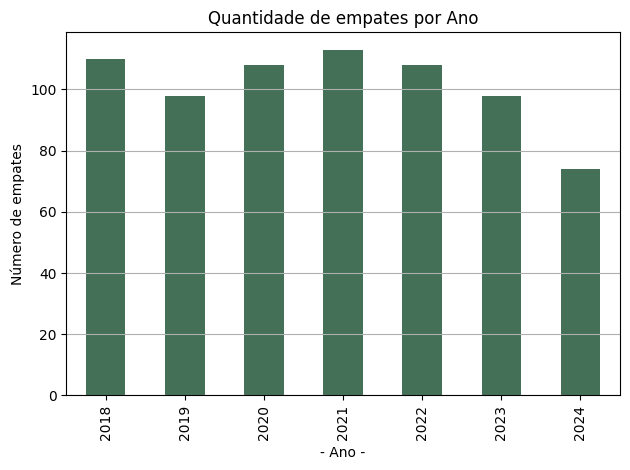

In [ ]:
plt.figure(figsize=(10, 5))
empates_por_ano.plot(kind='bar', x='ano_campeonato', y='quantidade_empates', color='#437057', legend=False)

plt.title('Quantidade de empates por Ano')
plt.xlabel('- Ano -')
plt.ylabel('Número de empates')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [ ]:
derrota_mandante = df_fut[(df_fut['gols_mandante'] < df_fut['gols_visitante']) & (df_fut['gols_visitante'] != 0)]
derrota_visitante = df_fut[(df_fut['gols_mandante'] > df_fut['gols_visitante']) & (df_fut['gols_mandante'] != 0)]

derrota_mandante_por_ano = derrota_mandante.groupby('ano_campeonato').size()
derrota_visitante_por_ano = derrota_visitante.groupby('ano_campeonato').size()

derrota_por_ano = derrota_mandante_por_ano + derrota_visitante_por_ano
# print(derrota_por_ano)

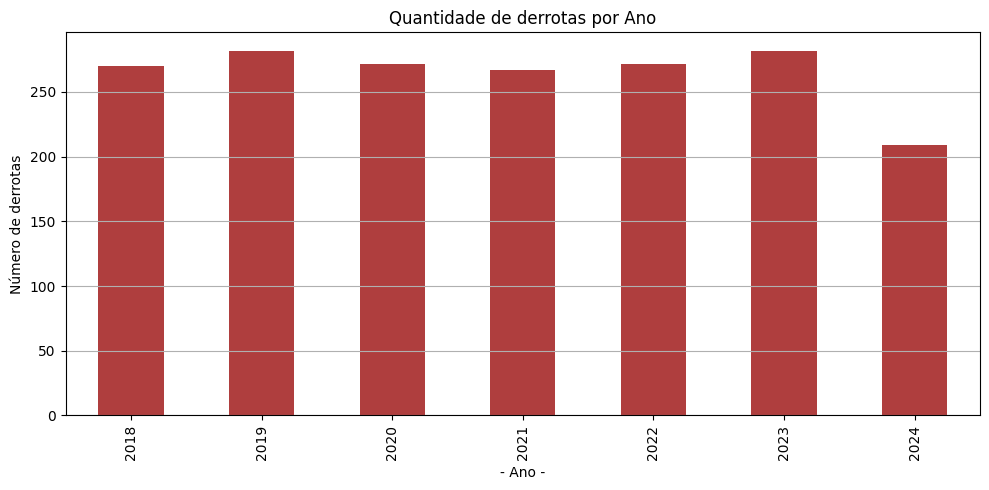

In [ ]:
plt.figure(figsize=(10, 5))
derrota_por_ano.plot(kind='bar', x='ano_campeonato', y='quantidade_derrota', color='#AF3E3E', legend=False)

plt.title('Quantidade de derrotas por Ano')
plt.xlabel('- Ano -')
plt.ylabel('Número de derrotas')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

## **Gols**

In [ ]:
gols_partida = df_fut['gols_mandante'] + df_fut['gols_visitante']
df_fut['gols_partida'] = gols_partida
print(df_fut["gols_partida"].describe())

count    2563.000000
mean        2.352712
std         1.521528
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        10.000000
Name: gols_partida, dtype: float64


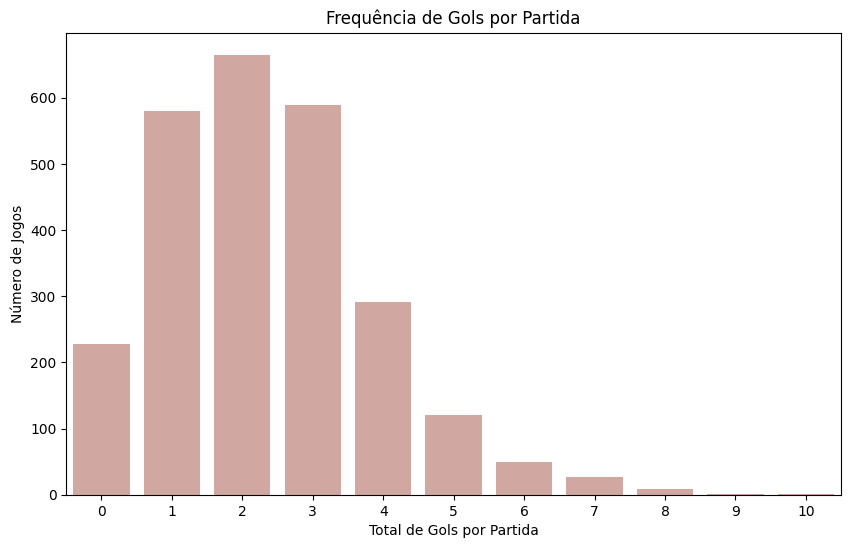

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x="gols_partida", data=df_fut, color="#D9A299")
plt.title("Frequência de Gols por Partida")
plt.xlabel("Total de Gols por Partida")
plt.ylabel("Número de Jogos")
plt.show()

1.3827545844713227


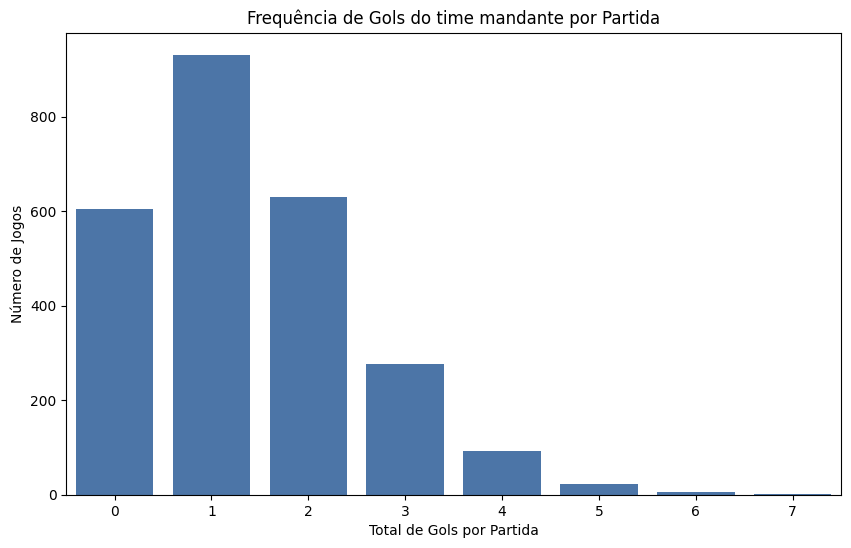

In [ ]:

print(df_fut["gols_mandante"].mean())
plt.figure(figsize=(10, 6))
sns.countplot(x="gols_mandante", data=df_fut, color="#3D74B6")
plt.title("Frequência de Gols do time mandante por Partida")
plt.xlabel("Total de Gols por Partida")
plt.ylabel("Número de Jogos")
plt.show()


0.9699570815450643


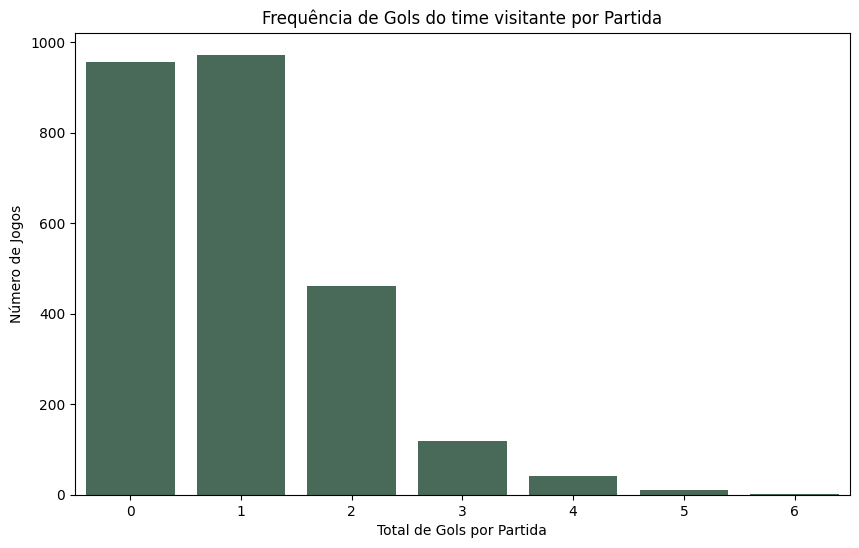

In [ ]:
print(df_fut["gols_visitante"].mean())
plt.figure(figsize=(10, 6))
sns.countplot(x="gols_visitante", data=df_fut, color="#437057")
plt.title("Frequência de Gols do time visitante por Partida")
plt.xlabel("Total de Gols por Partida")
plt.ylabel("Número de Jogos")
plt.show()


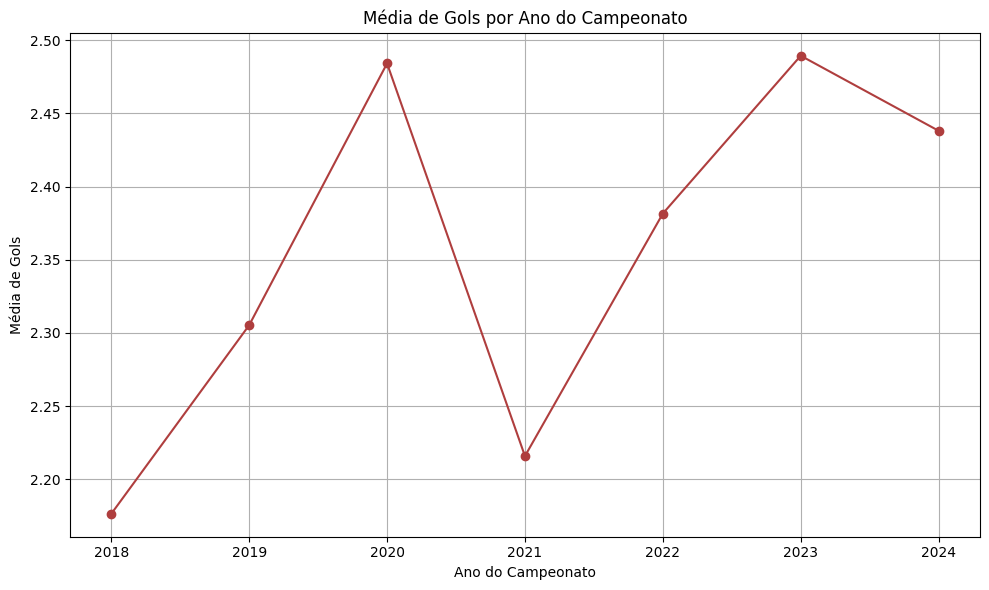

In [ ]:
media_gols_ano = df_fut.groupby('ano_campeonato')['gols_partida'].mean()

# Gráfico de linha
plt.figure(figsize=(10, 6))
plt.plot(media_gols_ano.index, media_gols_ano.values, marker='o', color='#AF3E3E')
plt.title('Média de Gols por Ano do Campeonato')
plt.xlabel('Ano do Campeonato')
plt.ylabel('Média de Gols')
plt.grid(True)
plt.tight_layout()
plt.show()

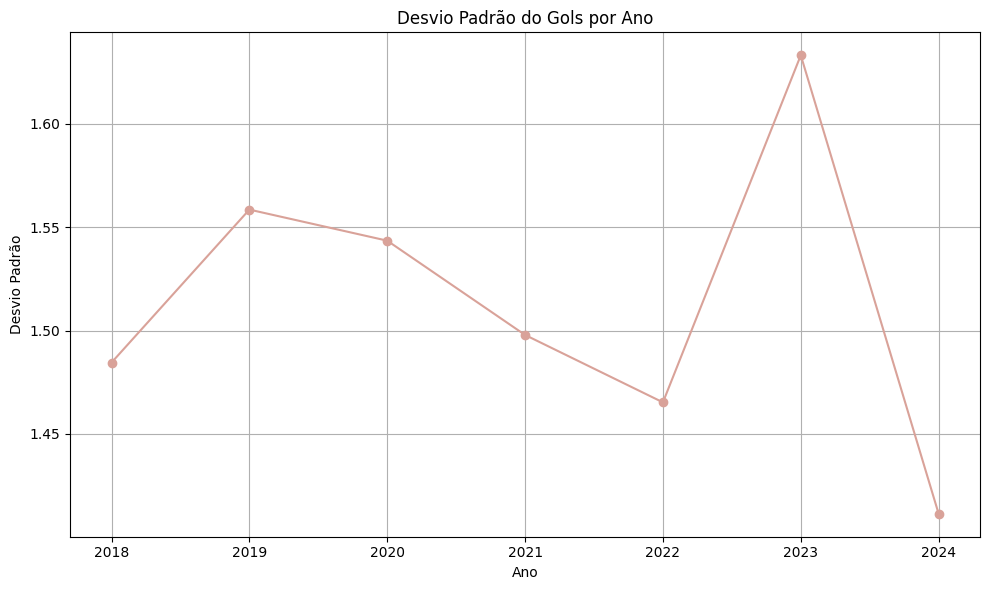

In [ ]:
# Calcula o desvio padrão por ano
desvio_padrao_gols = df_fut.groupby('ano_campeonato')['gols_partida'].std()

# Gera o gráfico
plt.figure(figsize=(10, 6))
plt.plot(desvio_padrao_gols.index, desvio_padrao_gols.values, marker='o', color='#D9A299')
plt.title('Desvio Padrão do Gols por Ano')
plt.xlabel('Ano')
plt.ylabel('Desvio Padrão')
plt.grid(True)
plt.tight_layout()
plt.show()

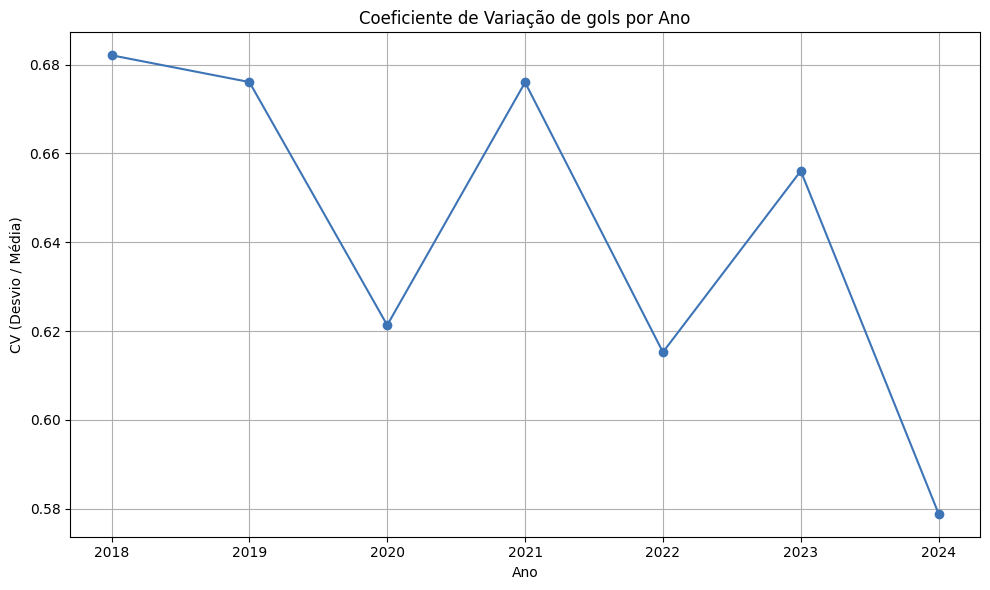

In [ ]:
cv_gols = desvio_padrao_gols / media_gols_ano

# Gera o gráfico
plt.figure(figsize=(10, 6))
plt.plot(cv_gols.index, cv_gols.values, marker = 'o', color='#3D74B6')
plt.title('Coeficiente de Variação de gols por Ano')
plt.xlabel('Ano')
plt.ylabel('CV (Desvio / Média)')
plt.grid(True)
plt.tight_layout()
plt.show()




## Insights iniciais:

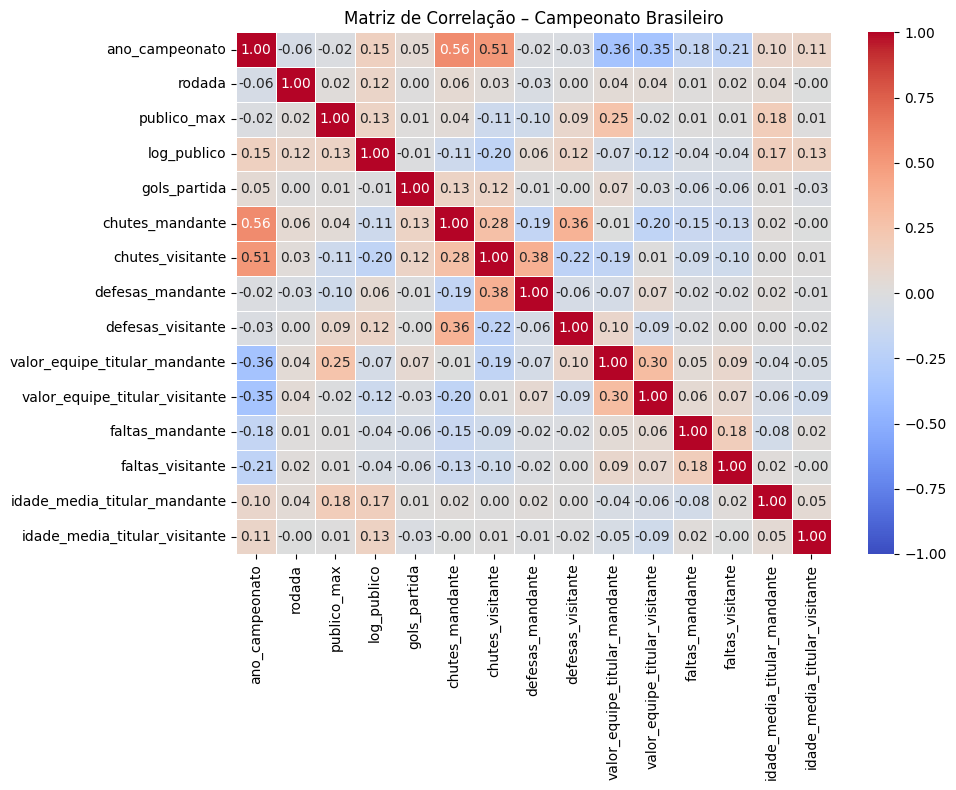

In [ ]:
cols_relevantes = ['ano_campeonato', 'rodada','publico_max', 'log_publico', 'gols_partida','chutes_mandante', 'chutes_visitante',
    'defesas_mandante', 'defesas_visitante','valor_equipe_titular_mandante', 'valor_equipe_titular_visitante', 'faltas_mandante', 'faltas_visitante',
     'idade_media_titular_mandante', 'idade_media_titular_visitante'
]


corr_matrix = df_fut[cols_relevantes].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,        # mostra números dentro dos quadrados
    fmt=".2f",         # duas casas decimais
    cmap="coolwarm",   # cores: azul (–1) → vermelho (+1)
    vmin=-1, vmax=1,
    linewidths=.5      # linhas divisórias mais visíveis
)
plt.title("Matriz de Correlação – Campeonato Brasileiro")
plt.tight_layout()
plt.show()

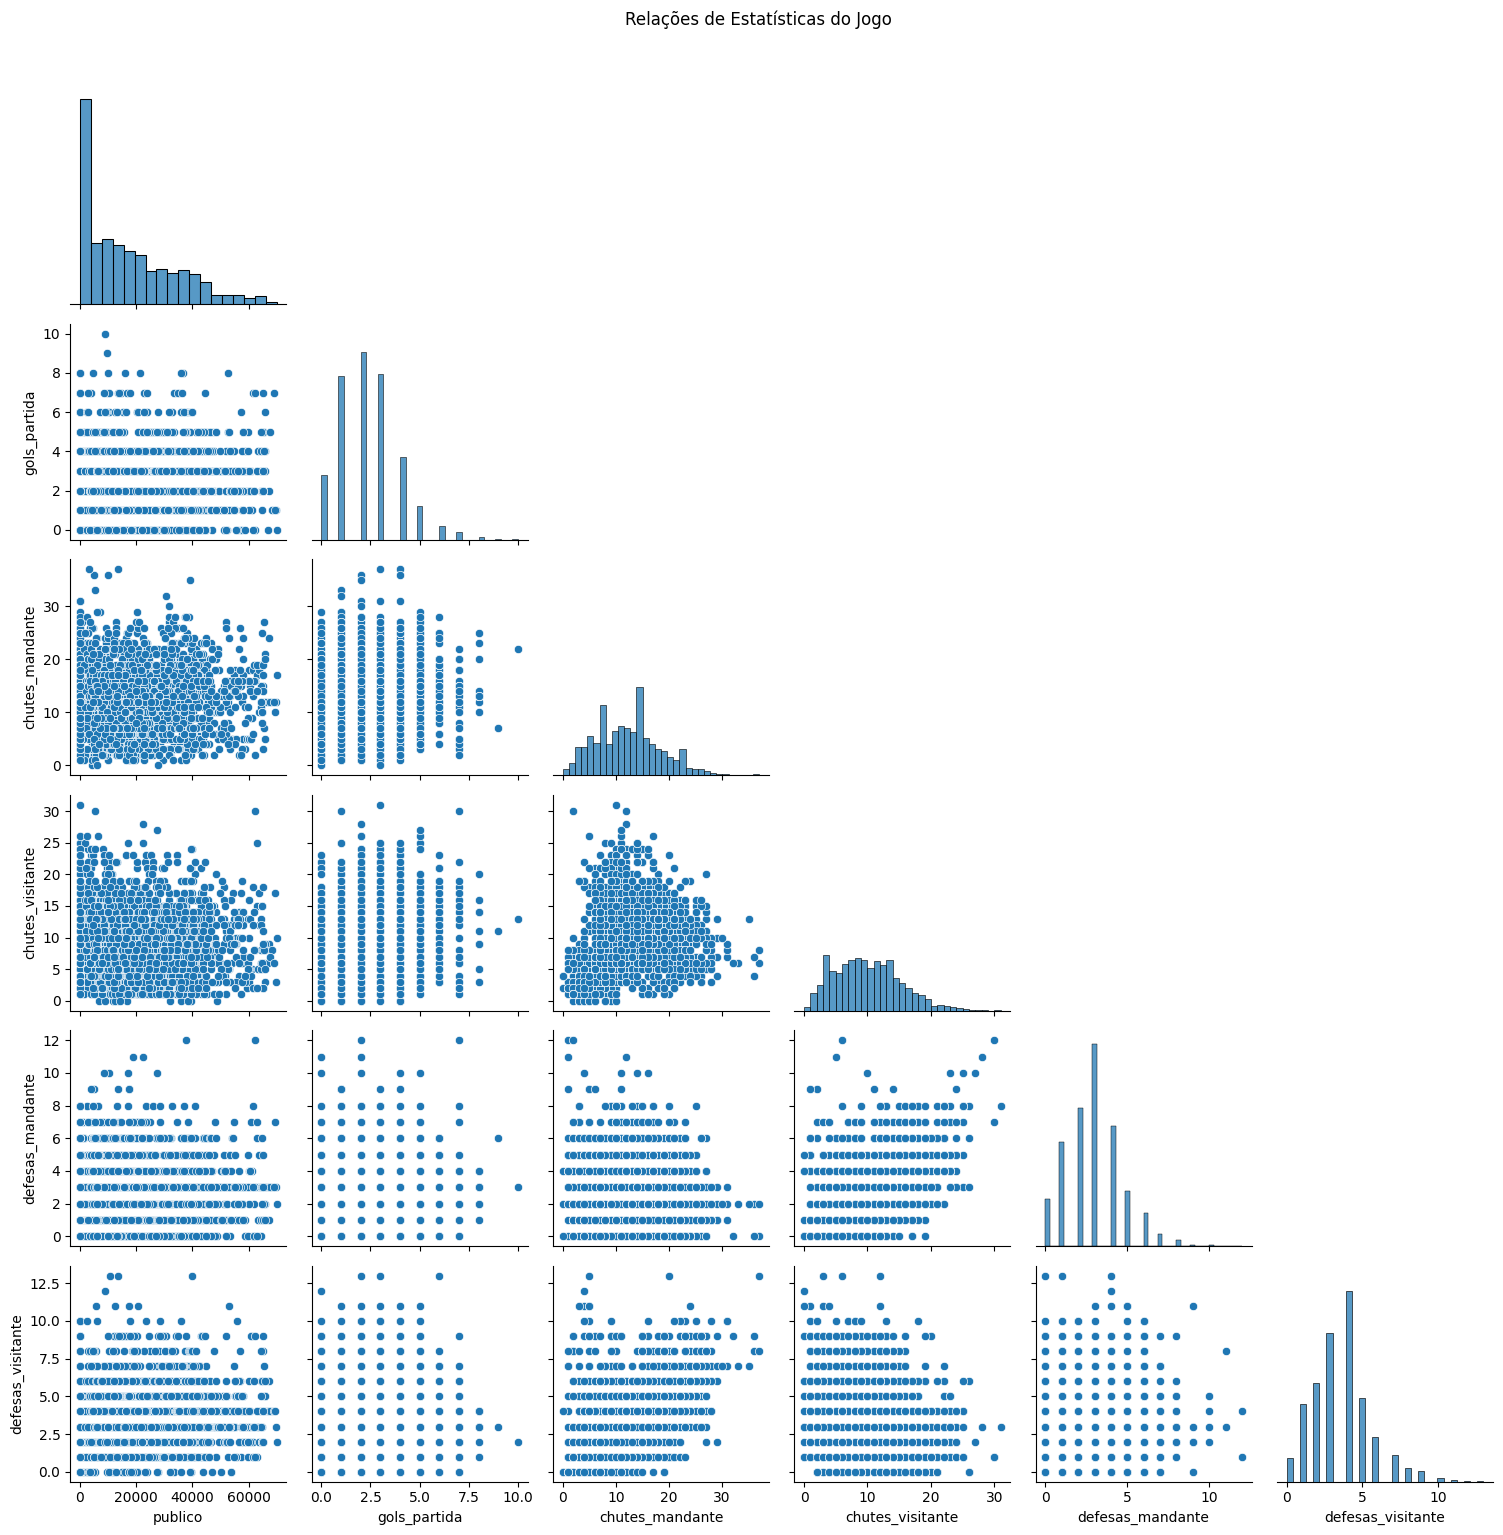

In [ ]:
cols_selecionadas = [
    'publico', 'gols_partida','chutes_mandante', 'chutes_visitante','defesas_mandante', 'defesas_visitante']

# Pairplot
sns.pairplot(df_fut[cols_selecionadas], diag_kind="hist",corner=True)
plt.suptitle("Relações de Estatísticas do Jogo", y=1.02)
plt.tight_layout()
plt.show()

### Insights da Base e Ánalise :

* Limpeza: A etapa de limpeza e preparação da base para ánalise, foi considerada a mais trabalhosa e díficil, pois a base por ser de muitos anos e a gravação dos dados pela fifa ter indo evoluído dentro desse período. Havia muita inconsistência na base, muitos dados nulos (principalmente nos anos mais antigos), dados gravados de forma incorreta, além da atenção especial aos dados de 2020 e 2021, ano que ocorreu a pandemia, temos mais variância ainda. Dito isto durante a preparação da base, houve várias incógnitas na hora de decidir quais abordagens seria utilizado em cada etapa, podendo talver ter sido feito de algumas maneiras diferentes.

* Jogos: Na análise de jogos, podemos ver que no geral os jogos tem uma variância não muito dispersa, mas aleatória durante os anos. Porém conseguimos ver uma tendência nos empates, podendo ser devido as mudanças de táticas neste perído.

* Público: Na análise do público observamos, uma dispersão maior nos anos de 2018 e 2019, e em 2020 e 2021, os gráficos disparam, pois ocorreu a pandemis, e nos anos seguintes 2022 em diante, ouve uma diminuição na variância de público se comparado com 2018 e 19.

* Gols: Os gols são uma parte mais complicada, pois a muita mais varância e aleatoriedade, já que é um resultado que depende de muitos fatores e ocasionaliedades. Porém em média os jogos tendem a ter cerca de 2 a 3 gols por partida. Além disso, conseguimos extrair uma tendência de gols quando o time é visitante ou mandante, os times mandantes tem uma média maior de gols do que os visitantes, isso pode acontecer mais devido a pressão da torcida, o que pode influênciar no psicológico dos jogadores.

Ánalise da correlação:

A partir da matriz de correlação, conseguimos perceber que as variáveis relacionadas a ataque e defesa se conectam de forma mais clara e fazem sentido, como o fato de que quando um time chuta mais, o outro tende a fazer mais defesas. Isso mostra um certo equilíbrio entre quem ataca e quem defende nos jogos.

Por outro lado, o público presente no estádio não parece ter muita ligação com o que acontece em campo, em termos de estatísticas. Mesmo que a torcida tenha importância emocional e psicológica, isso não ficou evidente nos números analisados.

Outra coisa que chamou atenção foi que o número de gols marcados não tem uma correlação forte com variáveis como os chutes. Isso mostra que o futebol é um esporte bem imprevisível, onde muitos fatores influenciam o resultado final além do volume de jogadas ofensivas.












Ánalise do pairplot:

Observando o pairplot vemos pouca correlação entre as váriaveis selecionadas, sendo muito difícil diferir os grupos nos gráficos. A baixa correlação é facilmente explicada pois o futebol é um jogo que possuí um placar baixo se comparado com outros esportes, e muita influência do acaso.


## `Regressão Público:`

###  Seleção de features e divisão dos dados

In [ ]:
df_encoded = df_fut.copy()
# Codificar variáveis categóricas com pd.get_dummies()
df_encoded = pd.get_dummies(df_encoded, columns=['estadio','time_mandante', 'arbitro', 'time_mandante', 'time_visitante', 'tecnico_mandante', 'tecnico_visitante'], drop_first=True)
df_encoded = df_encoded.select_dtypes(exclude=['datetime64[ns]', 'datetime64[ns, UTC]'])
df_encoded = df_encoded.drop(columns=['log_publico'])

In [ ]:

from sklearn.model_selection import train_test_split
# Copiar o original para preservar


# Lista original de features antes de codificar
features = [
    'ano_campeonato', 'rodada', 'publico_max',
    'valor_equipe_titular_mandante', 'valor_equipe_titular_visitante', 'time_mandante_Flamengo', 'colocacao_mandante'


]

#features = [col for col in df_encoded.columns if col != 'publico' ]
# Separar X e y

X = df_encoded[features]
y = df_encoded['publico']

# Separar em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### Treinado o modelo

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Treinar o modelo
model = DecisionTreeRegressor(random_state=42,max_depth=8, min_samples_leaf=5)
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=42)

### Obtendo as predições

In [ ]:
# Fazer previsões
y_pred = model.predict(X_test)

### Avaliando o modelo

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Avaliar o modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} g")
print(f"RMSE: {rmse:.2f} g")
print(f"R²: {r2:.2f}")

MAE: 5260.34 g
RMSE: 7921.96 g
R²: 0.79


### Gráfico: Valor Real vs Valor Previsto

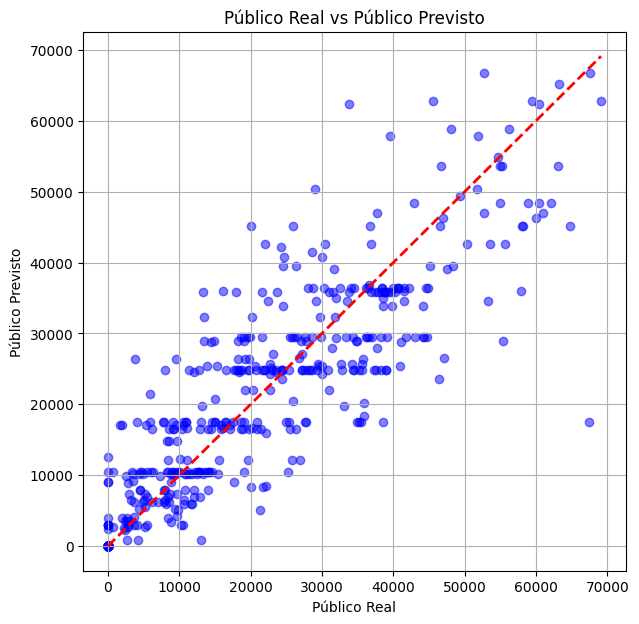

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Público Real')
plt.ylabel('Público Previsto')
plt.title('Público Real vs Público Previsto')
plt.grid(True)
plt.show()

### Visualização da Árvore de Decisão (Regressão)

 > As folhas da árvore mostram a previsão média do público nos jogos para cada subconjunto de dados.

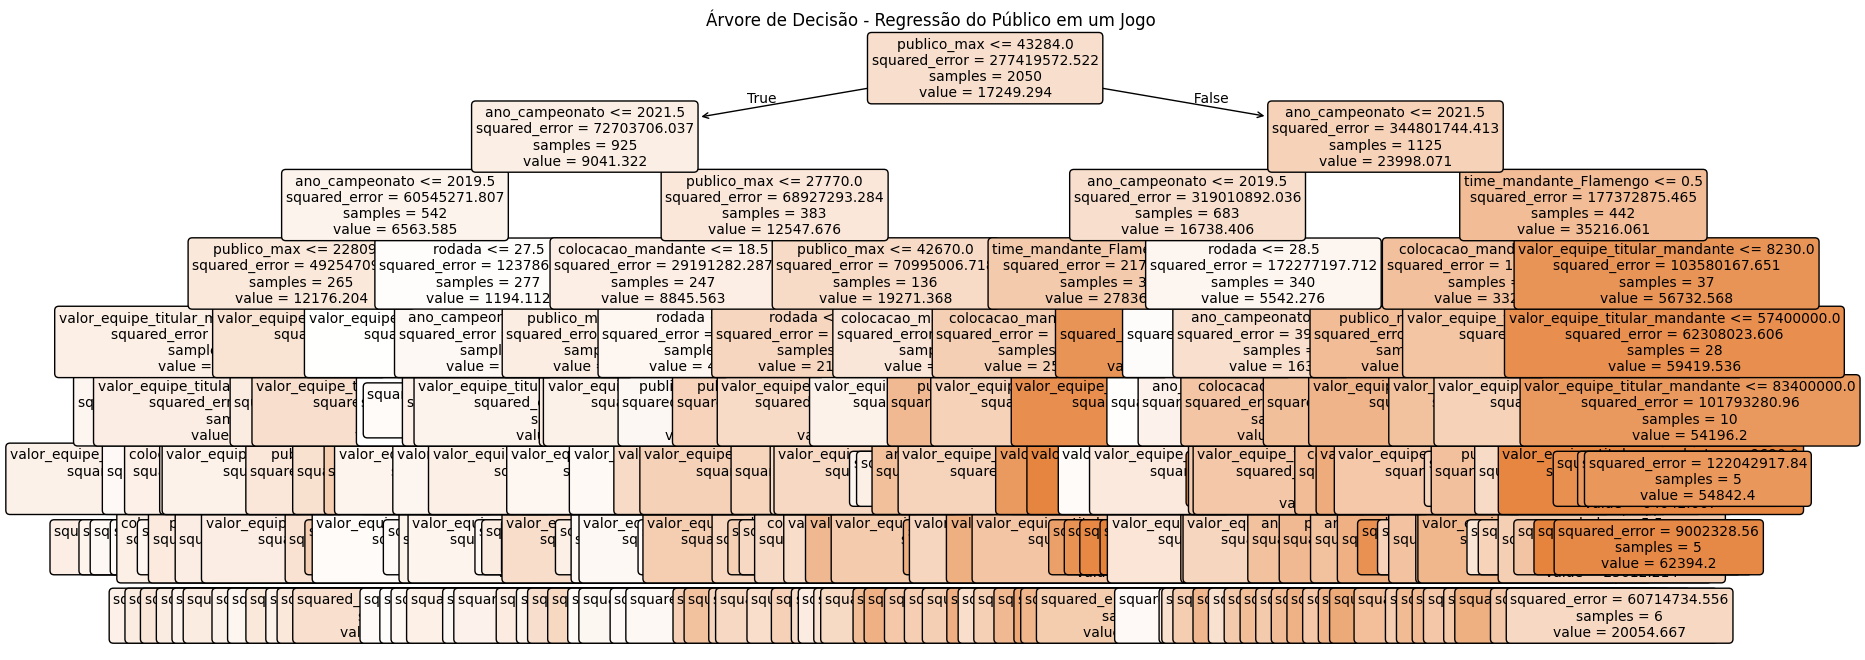

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão - Regressão do Público em um Jogo")
plt.show()

### Importância das Variáveis (Feature Importance)

In [ ]:
# Obter importância das features
importances = model.feature_importances_
features = X.columns

# Criar DataFrame para visualização
feat_imp = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Exibir
feat_imp


,Feature,Importance
0,ano_campeonato,0.473595
2,publico_max,0.287168
6,time_mandante_Flamengo,0.087191
1,rodada,0.056347
3,valor_equipe_titular_mandante,0.041340
7,colocacao_mandante,0.035914
4,valor_equipe_titular_visitante,0.018446
5,time_mandante_Flamengo,0.000000


### Observações da regressão

Na regressão de público por jogo, podemos ver no gráfico de valor real vs valor previsto, que o modelo tende a acertar mais em jogos com público médio a baixo, e tem maior dispersão em jogos com muito público.
Além disso a várias features que praticamente não importam na previsão, sendo a maioria estadios e times mandantes, porém como eles vem com a coluna quando aplicamos o dummies, é ruim de tira-los.
Uma observação que podemos fazer com essa regressão é que o ano é feature que mais importa, isso já era esperado pois nos anos com pandemia a maioria dos jogos teve público zero.

MAE (5250): Este valor na métrica MAE indica que o modelo erra cerca de 5250 (+-) pessoas do público em um jogo.

RMSE (7921): O RMSE mesmo tendo um valor maior que o MAE (o esperado) não passa muito longe, o que indica que não a prensença de muitos outliers.

R2 (0.79):  O valor 0,79 na métrica r2, indica que este modelo consegue explicar cerca de 79% do público nos jogos, sendo um valor muito bom, pois a muitas implicâncias devido a pandemia

### Escolha das features

Na escolha das features, foi feito um teste amplo, com um for em todas as colunas (depois de utilizar o get_dummies nas colunas "string" e de ter tirado a coluna log_publico). Então foi observado as colunas que apresentavam maior importância, e então colocamos essas colunas direto nas features, para melhor visualização. Então foi feito vários testes de modificando a profundidade e largura da árvore, e o melhor resultado foi 0,79. Acreditamos que seja um valor muito bom.

## `Regressão Chutes em um Jogo:`

###  Seleção de features e divisão dos dados

In [ ]:
df_encoded = df_fut.copy()
# Codificar variáveis categóricas com pd.get_dummies()
df_encoded = pd.get_dummies(df_encoded, columns=['estadio','time_mandante', 'arbitro', 'time_mandante', 'time_visitante', 'tecnico_mandante', 'tecnico_visitante'], drop_first=True)
df_encoded = df_encoded.select_dtypes(exclude=['datetime64[ns]', 'datetime64[ns, UTC]'])

df_encoded['chutes_jogo'] = df_encoded['chutes_mandante'] + df_encoded['chutes_visitante']
df_encoded = df_encoded.drop(columns=[ 'chutes_mandante', 'chutes_visitante'])

In [ ]:
from sklearn.model_selection import train_test_split


# Lista original de features antes de codificar
features = [
    'ano_campeonato', 'defesas_mandante', 'impedimentos_mandante', 'defesas_visitante', 'chutes_bola_parada_visitante', 'rodada',
    'chutes_fora_visitante', 'chutes_fora_mandante', 'chutes_bola_parada_mandante',
]





#features = [col for col in df_encoded.columns if col != 'chutes_jogo' ]

# Separar X e y

X = df_encoded[features]
y = df_encoded['chutes_jogo']


# Separar em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### Treinado o modelo

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Treinar o modelo
model = DecisionTreeRegressor(random_state=42,max_depth=8, min_samples_leaf=3)
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=8, min_samples_leaf=3, random_state=42)

### Obtendo as predições

In [ ]:
# Fazer previsões
y_pred = model.predict(X_test)

### Avaliando o modelo

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Avaliar o modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} g")
print(f"RMSE: {rmse:.2f} g")
print(f"R²: {r2:.2f}")

MAE: 3.05 g
RMSE: 4.22 g
R²: 0.79


### Gráfico: Valor Real vs Valor Previsto

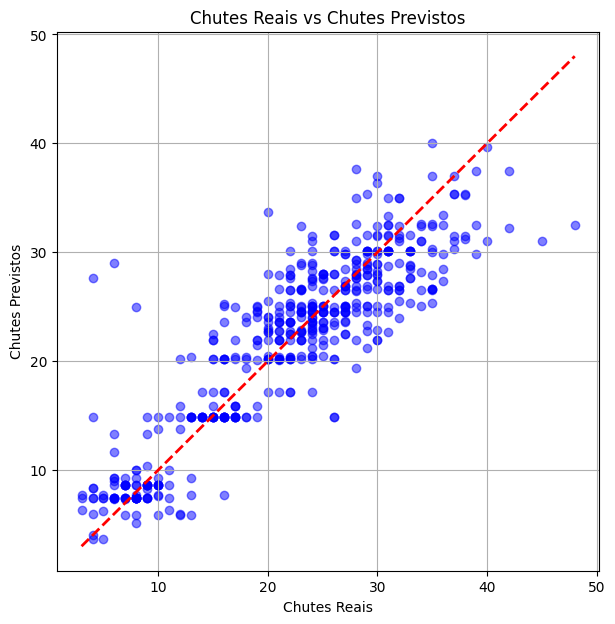

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Chutes Reais')
plt.ylabel('Chutes Previstos')
plt.title('Chutes Reais vs Chutes Previstos')
plt.grid(True)
plt.show()

### Visualização da Árvore de Decisão (Regressão)

 > As folhas da árvore mostram a previsão média do público nos jogos para cada subconjunto de dados.

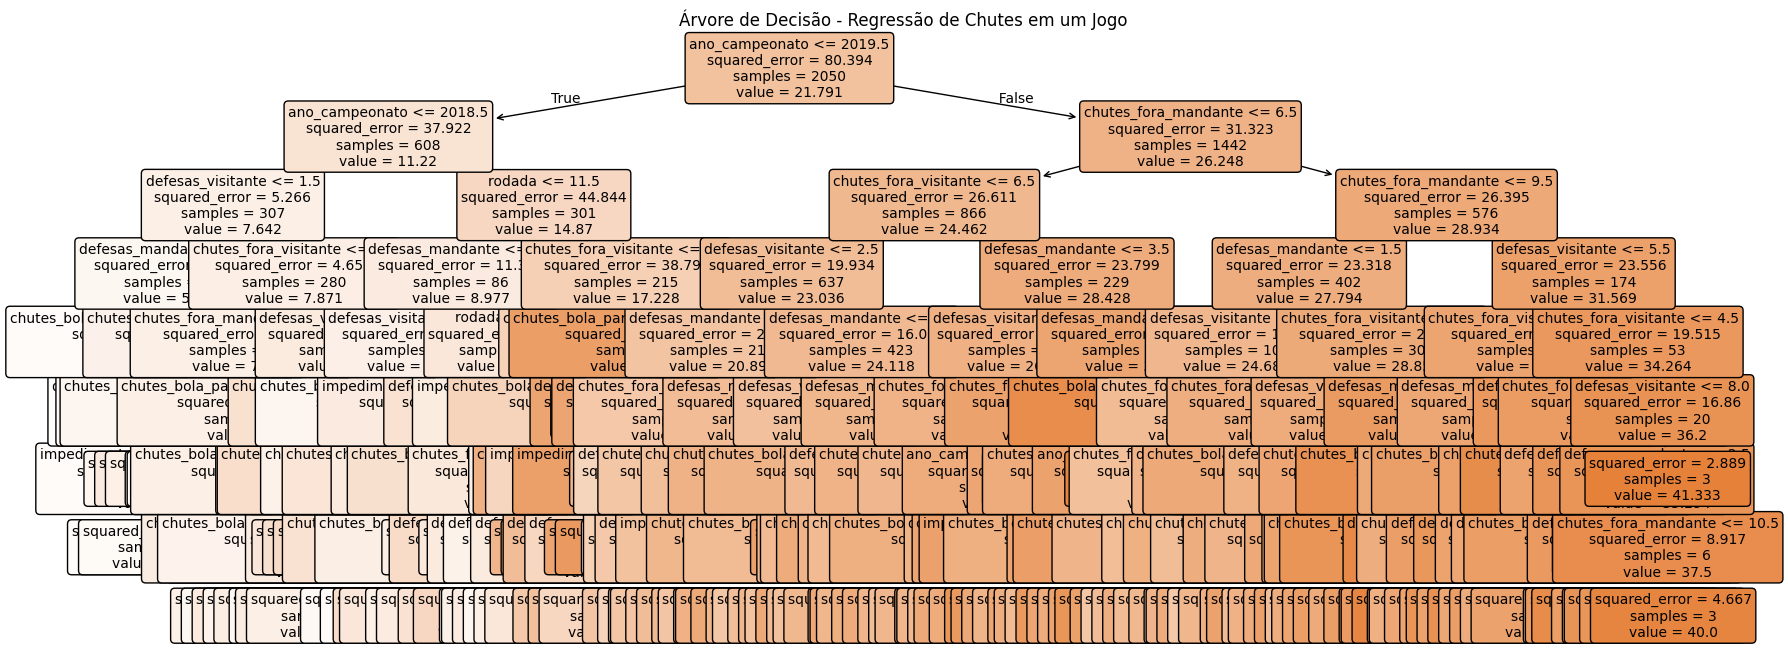

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão - Regressão de Chutes em um Jogo")
plt.show()

### Importância das Variáveis (Feature Importance)

In [ ]:
# Obter importância das features
importances = model.feature_importances_
features = X.columns

# Criar DataFrame para visualização
feat_imp = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Exibir
feat_imp


,Feature,Importance
0,ano_campeonato,0.706315
7,chutes_fora_mandante,0.085352
6,chutes_fora_visitante,0.076899
3,defesas_visitante,0.041575
1,defesas_mandante,0.039059
5,rodada,0.031634
8,chutes_bola_parada_mandante,0.009109
4,chutes_bola_parada_visitante,0.005168
2,impedimentos_mandante,0.004889


### Informações da regressão e métricas de avaliação:


No gráfico de dispersão podemos ver uma tendência linear dos pontos, com poucos pontos fora do alinhamento. Indicando erros maiores em jogos com muitas ou poucas faltas.

Observando a árvore de decisão podemos ver que a váriavel que mais influência é o ano do campeonato, o que surpreende, podendo ser por mudanças das táticas dos jogos, com aumento de chutes durante os anos, em seguida vem os tipos de chutes, o que já faz mais sentido, pois os chutes agregam na várivel final de chutes.

MAE (3,21): Este resultado significa que em média o modelo erra cerca de 3 chutes por jogo do valor real.

RMSE (4,38): Essa métrica penaliza bastante os erros maiores, porém vemos que mesmo o valor sendo maior que o MAE, não está longe, indicando poucos outliers extremos.

R2 (0,70): Essa métrica com este valor, indica que cerca de 70% dos chutes em um jogo podem ser explicadas pelas váriaveis usadas no modelo, sendo considerado um bom resultado no cenário de previsão.


# Ánalise Times

## Feactures

In [ ]:
#Feactures de resultados.

# colunas binárias
# Duas Colunas o time que venceu recebe 1, se o número de gols for igual os dois times ficam 0

df_fut["mandante_venceu"] = (df_fut["gols_mandante"] > df_fut["gols_visitante"]).astype(int)
df_fut["visitante_venceu"] = (df_fut["gols_visitante"] > df_fut["gols_mandante"]).astype(int)


# coluna única (3 categorias)
# Uma coluna, se o time mandante ganhou coluna recebe 1, se deu empate 0, e se o time visitante ganhou -1

df_fut["resultado"] = df_fut["gols_mandante"].sub(df_fut["gols_visitante"]).apply(
    lambda x: 1 if x > 0 else (-1 if x < 0 else 0)
)


In [ ]:
df_fut.head(5)

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante,log_publico,log_publico_max,gols_partida,mandante_venceu,visitante_venceu,resultado
0,2018,2018-10-06,28,Arena da Baixada,Raphael Claus,11443,42372,Atlético-PR,América-MG,Tiago Nunes,...,4,3,4,1,9.345221,10.654267,4,1,0,1
1,2018,2018-10-02,27,Estádio Durival Britto e Silva,Flavio Rodrigues de Souza,3894,20083,Paraná,Vasco da Gama,Claudinei Oliveira,...,5,3,10,7,8.267449,9.907679,2,0,0,0
2,2018,2018-08-23,20,Estádio Durival Britto e Silva,Péricles Bassols Pegado Cortez,8561,20083,Paraná,São Paulo,Claudinei Oliveira,...,2,3,9,7,9.055089,9.907679,2,0,0,0
3,2018,2018-11-18,35,Estádio Cícero Pompeu de Toledo,Héber Lopes,14058,67428,São Paulo,Cruzeiro,André Jardine,...,4,0,5,4,9.551018,11.118830,1,1,0,1
4,2018,2018-10-30,31,Estádio Governador Plácido Castelo,Wagner Reway,37394,60326,Ceará SC,Atlético-MG,Lisca,...,6,2,3,7,10.529292,11.007535,3,1,0,1


In [ ]:
# Criar DataFrame para mandantes
mandante = df_fut.rename(columns={
    "time_mandante": "time",
    "gols_mandante": "gols_pro",
    "gols_visitante": "gols_contra",
    "chutes_mandante": "chutes",
    "chutes_visitante": "chutes_contra",
    "impedimentos_mandante": "impedimentos",
    "defesas_mandante": "defesas",
    "faltas_mandante": "faltas",
    "escanteios_mandante": "escanteios",
    "faltas_visitante": "faltas_contra",
    "idade_media_titular_mandante": "idade",
    "mandante_venceu": "vitoria",
    "visitante_venceu": "derrota",
}).copy()
mandante["local"] = "casa"

# Criar DataFrame para visitantes
visitante = df_fut.rename(columns={
    "time_visitante": "time",
    "gols_visitante": "gols_pro",
    "gols_mandante": "gols_contra",
    "chutes_visitante": "chutes",
    "chutes_mandante": "chutes_contra",
    "faltas_mandante": "faltas_contra",
    "impedimentos_visitante": "impedimentos",
    "defesas_visitante": "defesas",
    "escanteios_visitante": "escanteios",
    "faltas_visitante": "faltas",
    "idade_media_titular_visitante": "idade",
    "mandante_venceu": "derrota",
    "visitante_venceu": "vitoria",

}).copy()

visitante["local"] = "fora"

# Concatenar
df_concatenado = pd.concat([mandante, visitante], ignore_index=True)

# Feature de resultado (1 vitória, 0 empate, -1 derrota)
df_concatenado["resultado"] = df_concatenado["gols_pro"].sub(df_concatenado["gols_contra"]).apply(lambda x: 1 if x>0 else (-1 if x<0 else 0))

# Pontos (3 vitória, 1 empate, 0 derrota)
df_concatenado["pontos"] = df_concatenado["resultado"].apply(lambda x: 3 if x==1 else (1 if x==0 else 0))

df = df_concatenado


In [ ]:

# Criar coluna adversário a partir da rodada
df["adversario"] = df.groupby("rodada")["time"].transform(lambda x: x[::-1].values)

In [ ]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time,time_visitante,tecnico_mandante,...,derrota,resultado,local,time_mandante,idade_media_titular_mandante,escanteios_mandante,defesas_mandante,impedimentos_mandante,pontos,adversario
0,2018,2018-10-06,28,Arena da Baixada,Raphael Claus,11443,42372,Atlético-PR,América-MG,Tiago Nunes,...,0,1,casa,NaN,NaN,NaN,NaN,NaN,3,Grêmio
1,2018,2018-10-02,27,Estádio Durival Britto e Silva,Flavio Rodrigues de Souza,3894,20083,Paraná,Vasco da Gama,Claudinei Oliveira,...,0,0,casa,NaN,NaN,NaN,NaN,NaN,1,Cruzeiro
2,2018,2018-08-23,20,Estádio Durival Britto e Silva,Péricles Bassols Pegado Cortez,8561,20083,Paraná,São Paulo,Claudinei Oliveira,...,0,0,casa,NaN,NaN,NaN,NaN,NaN,1,Vasco da Gama
3,2018,2018-11-18,35,Estádio Cícero Pompeu de Toledo,Héber Lopes,14058,67428,São Paulo,Cruzeiro,André Jardine,...,0,1,casa,NaN,NaN,NaN,NaN,NaN,3,EC Bahia
4,2018,2018-10-30,31,Estádio Governador Plácido Castelo,Wagner Reway,37394,60326,Ceará SC,Atlético-MG,Lisca,...,0,1,casa,NaN,NaN,NaN,NaN,NaN,3,Atlético-GO


## Times

1- Qual a média de pontos dos times de 2018 a 2024? Quais times tem a maior média de pontos somando esses anos?

/tmp/ipython-input-3928475877.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=media_pontos.values, y=media_pontos.index, palette="Blues_r")


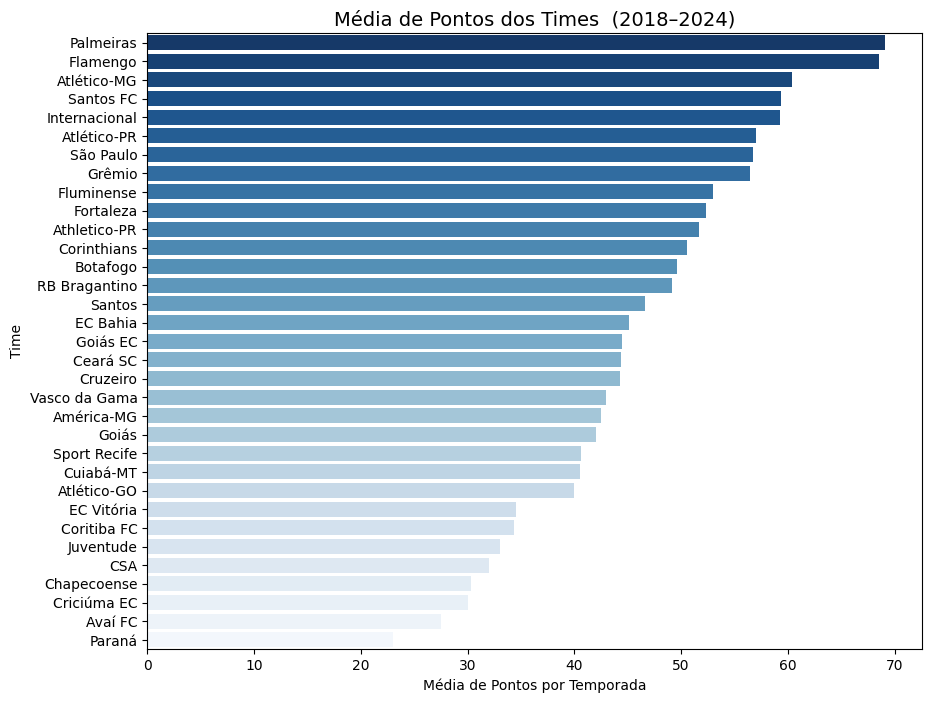

In [ ]:

# Soma os pontos por time e ano
pontos_ano = df.groupby(["time", "ano_campeonato"])["pontos"].sum().reset_index()

# Calcula a média das temporadas (2018–2024) por time
media_pontos = pontos_ano.groupby("time")["pontos"].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(10,8))
sns.barplot(x=media_pontos.values, y=media_pontos.index, palette="Blues_r")

plt.title("Média de Pontos dos Times  (2018–2024)", fontsize=14)
plt.xlabel("Média de Pontos por Temporada")
plt.ylabel("Time")
plt.show()

2- Quais os times foram mais ofensivos ?

TOP 5 TIMES MAIS OFENSIVOS:
                  chutes  gols_pro  escanteios  score_ofensivo
time                                                          
RB Bragantino  14.666667  1.300000    5.866667       21.833333
Palmeiras      13.132296  1.603113    6.167315       20.902724
Flamengo       12.347656  1.734375    6.429688       20.511719
Criciúma EC    13.464286  1.178571    4.857143       19.500000
Atlético-MG    11.929412  1.439216    6.047059       19.415686


/tmp/ipython-input-3384196735.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ofensivos["score_ofensivo"], y=ofensivos.index, palette="Reds_r")


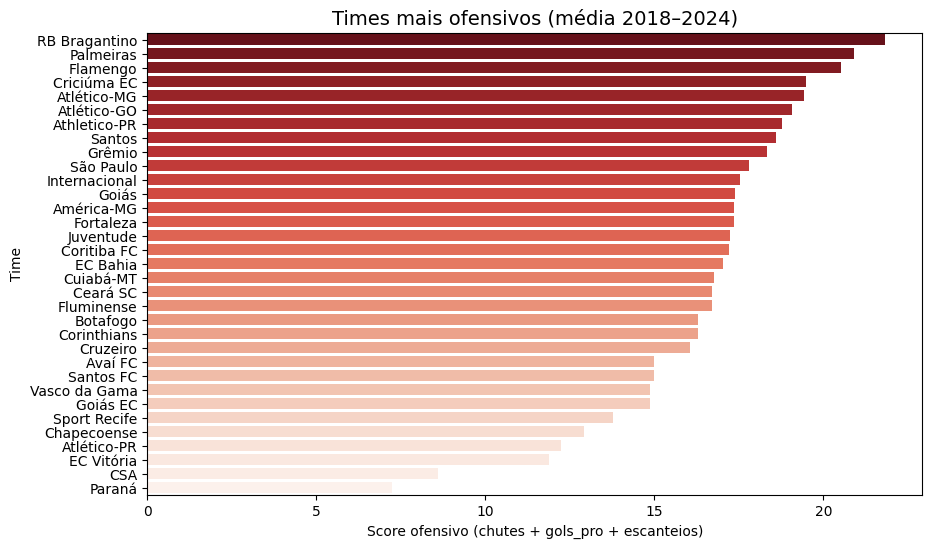

In [ ]:
ofensivas = ["chutes", "gols_pro", "escanteios"]

# Média por time
ofensivos = df.groupby("time")[ofensivas].mean()

# Ordena por soma das médias
ofensivos["score_ofensivo"] = ofensivos.sum(axis=1)
ofensivos = ofensivos.sort_values("score_ofensivo", ascending=False)

print("TOP 5 TIMES MAIS OFENSIVOS:")
print(ofensivos.head(5))

# Plot gráfico
plt.figure(figsize=(10,6))
sns.barplot(x=ofensivos["score_ofensivo"], y=ofensivos.index, palette="Reds_r")
plt.title("Times mais ofensivos (média 2018–2024)", fontsize=14)
plt.xlabel("Score ofensivo (chutes + gols_pro + escanteios)")
plt.ylabel("Time")
plt.show()

3- Quais times foram mais eficientes ?

TOP 5 TIMES MAIS EFICIENTES:
time
Atlético-PR    0.258824
EC Vitória     0.257382
Paraná         0.226389
Santos FC      0.219977
Flamengo       0.177616
Name: eficiencia, dtype: float64


/tmp/ipython-input-973793620.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eficientes.values, y=eficientes.index, palette="Greens_r")


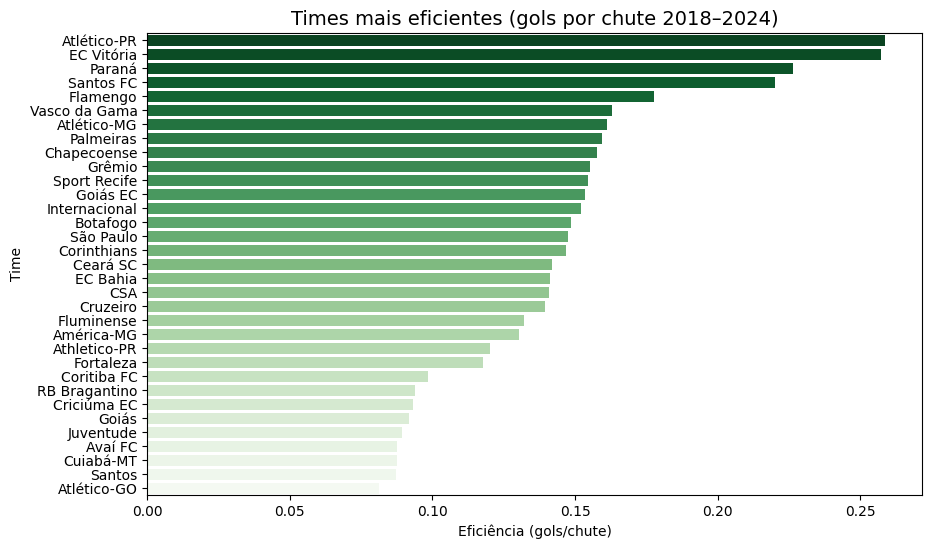

In [ ]:
# Criar coluna de eficiência por partida
df["eficiencia"] = np.where(df["chutes"] > 0,
                            df["gols_pro"] / df["chutes"],
                            np.nan)

# Calcular a média da eficiência por time
eficientes = df.groupby("time")["eficiencia"].mean().sort_values(ascending=False)

print("TOP 5 TIMES MAIS EFICIENTES:")
print(eficientes.head(5))

# Plot gráfico
plt.figure(figsize=(10,6))
sns.barplot(x=eficientes.values, y=eficientes.index, palette="Greens_r")
plt.title("Times mais eficientes (gols por chute 2018–2024)", fontsize=14)
plt.xlabel("Eficiência (gols/chute)")
plt.ylabel("Time")
plt.show()

4- Quais os times mais defensivos ?

TOP 5 TIMES MAIS DEFENSIVOS:
             faltas_contra   defesas  score_defensivo
time                                                 
CSA              18.763158  4.605263        23.368421
Santos FC        17.517544  3.175439        20.692982
Goiás EC         16.500000  3.763158        20.263158
Avaí FC          16.710526  3.223684        19.934211
Chapecoense      15.912281  3.894737        19.807018


/tmp/ipython-input-3134507009.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=defensivos["score_defensivo"], y=defensivos.index, palette="Blues_r")


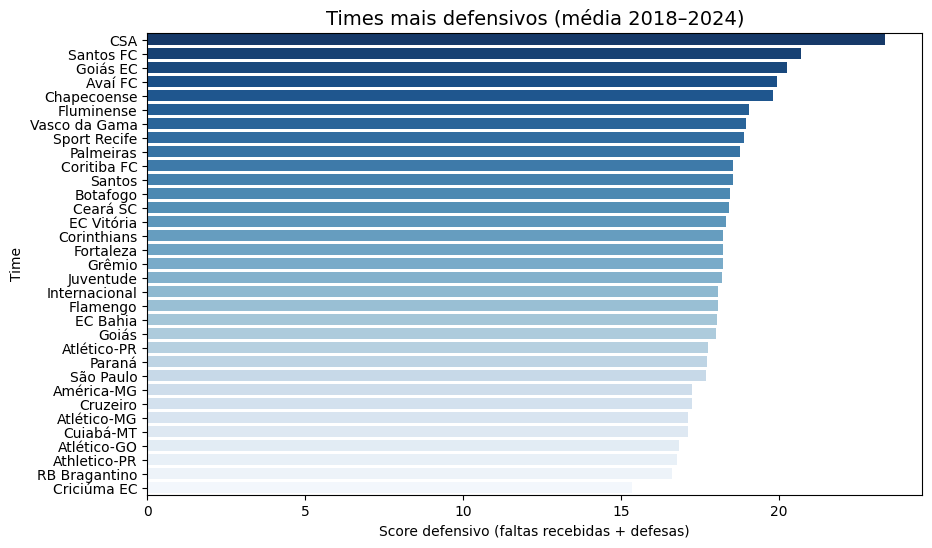

In [ ]:
# Times mais defensivos
defensivas = ["faltas_contra", "defesas"]

defensivos = df.groupby("time")[defensivas].mean()

# Ordena por soma das médias (critério de "defensividade")
defensivos["score_defensivo"] = defensivos.sum(axis=1)
defensivos = defensivos.sort_values("score_defensivo", ascending=False)

print("TOP 5 TIMES MAIS DEFENSIVOS:")
print(defensivos.head(5))

# Plot gráfico
plt.figure(figsize=(10,6))
sns.barplot(x=defensivos["score_defensivo"], y=defensivos.index, palette="Blues_r")
plt.title("Times mais defensivos (média 2018–2024)", fontsize=14)
plt.xlabel("Score defensivo (faltas recebidas + defesas)")
plt.ylabel("Time")
plt.show()

TOP 5 TIMES MAIS EFICIENTES DEFENSIVAMENTE:
time
Paraná         1.013628
Atlético-PR    0.985056
EC Vitória     0.729400
CSA            0.662952
Chapecoense    0.623728
Name: eficiencia, dtype: float64


/tmp/ipython-input-2357869286.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eficientes.values, y=eficientes.index, palette="Greens_r")


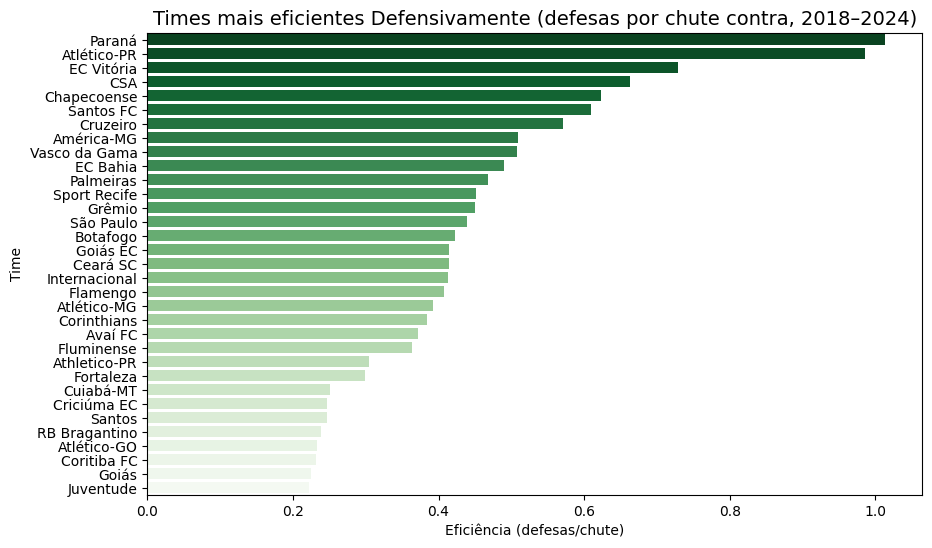

In [ ]:
# Criar coluna de eficiência por partida
df["eficiencia"] = np.where(df["chutes_contra"] > 0,
                            df["defesas"] / df["chutes_contra"],
                            np.nan)


df_filtro = df[df["ano_campeonato"].between(2018, 2024)]

eficientes = df_filtro.groupby("time")["eficiencia"].mean().sort_values(ascending=False)

print("TOP 5 TIMES MAIS EFICIENTES DEFENSIVAMENTE:")
print(eficientes.head(5))

# Plot gráfico
plt.figure(figsize=(10,6))
sns.barplot(x=eficientes.values, y=eficientes.index, palette="Greens_r")
plt.title("Times mais eficientes Defensivamente (defesas por chute contra, 2018–2024)", fontsize=14)
plt.xlabel("Eficiência (defesas/chute)")
plt.ylabel("Time")
plt.show()

5- Qual a porcentagem de pontos que cada time faz por rodada ?

TOP 5 TIMES MAIS IRREGULARES (maior desvio padrão de pontos):
time
Atlético-PR    1.350676
Fluminense     1.339648
Fortaleza      1.330293
Botafogo       1.327904
Grêmio         1.327629
Name: pontos, dtype: float64


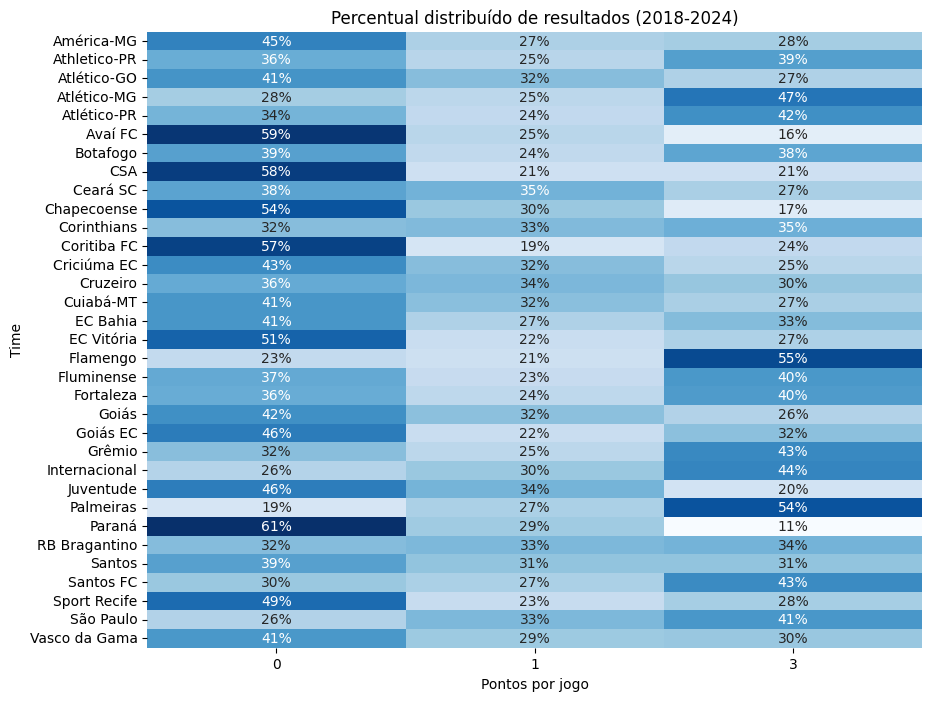

In [ ]:

# Calcular desvio padrão dos pontos por time
desvios = df.groupby("time")["pontos"].std().sort_values(ascending=False)

print("TOP 5 TIMES MAIS IRREGULARES (maior desvio padrão de pontos):")
print(desvios.head(5))

# Ordenar times pelo desvio padrão para o gráfico
ordem_times = desvios.index

freq = df_filtro.groupby("time")["pontos"].value_counts(normalize=True).unstack().fillna(0)

plt.figure(figsize=(10,8))
sns.heatmap(freq, annot=True, cmap="Blues", cbar=False, fmt=".0%")
plt.title("Percentual distribuído de resultados (2018-2024)")
plt.xlabel("Pontos por jogo")
plt.ylabel("Time")
plt.yticks(rotation=0)
plt.show()


## Rivalidades

### **Quer saber as estástisticas do seu time com os rivais? **

### Função de Rivalidades

In [ ]:
def rivalidades(df, time1, time2, anos=None, plot=True):
    # filtro básico
    base = df[df["time"].isin([time1, time2])].copy()
    if anos is not None:
        # anos pode ser tupla (2018, 2024) ou lista de anos
        if isinstance(anos, tuple):
            base = base[base["ano_campeonato"].between(anos[0], anos[1])]
        else:
            base = base[base["ano_campeonato"].isin(anos)]

    # parear os dois lados do mesmo jogo (ano+rdada)
    tabela = (base.pivot_table(index=["ano_campeonato", "rodada"],
                               columns="time", values="gols_pro", aggfunc="sum")
                    .reindex(columns=[time1, time2]))
    # manter só partidas onde os dois aparecem
    tabela = tabela.dropna(how="any")

    jogos = len(tabela)
    if jogos == 0:
        print(f"Nenhum jogo encontrado entre {time1} e {time2} no período filtrado.")
        return None

    g1 = tabela[time1].to_numpy()
    g2 = tabela[time2].to_numpy()

    v1 = int(np.sum(g1 > g2))
    v2 = int(np.sum(g2 > g1))
    emp = int(np.sum(g1 == g2))

    m1 = float(np.mean(g1))
    m2 = float(np.mean(g2))

    resumo = {
        "Jogos": jogos,
        f"Vitórias {time1}": v1,
        f"Vitórias {time2}": v2,
        "Empates": emp,
        f"Média gols {time1}": round(m1, 2),
        f"Média gols {time2}": round(m2, 2),
    }

    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # vitória,empates e derrotas
        cats = [f"Vitórias {time1}", "Empates", f"Vitórias {time2}"]
        vals = [v1, emp, v2]
        axes[0].bar(cats, vals)
        axes[0].set_title(f"Resultados entre {time1} e {time2} ({jogos} jogos)")
        axes[0].set_ylabel("Nº de jogos")
        for i, v in enumerate(vals):
            axes[0].text(i, v + 0.05, str(v), ha="center", va="bottom")

        #  médias de gols
        cats2 = [time1, time2]
        vals2 = [m1, m2]
        axes[1].bar(cats2, vals2)
        axes[1].set_title("Média de gols marcados")
        axes[1].set_ylabel("Gols por jogo")
        for i, v in enumerate(vals2):
            axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center", va="bottom")

        plt.tight_layout()
        plt.show()

    return resumo

### Times de São Paulo

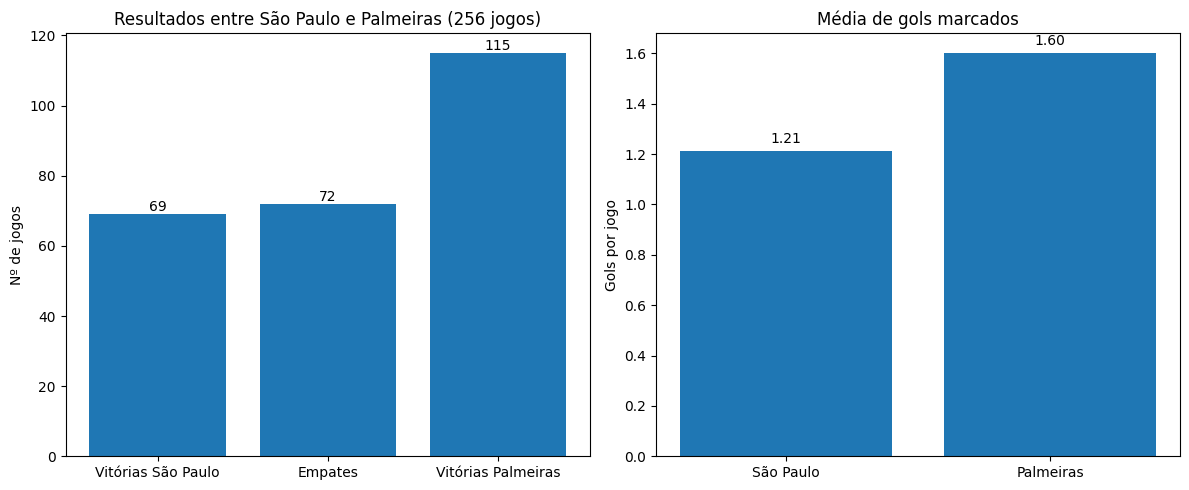

{'Jogos': 256, 'Vitórias São Paulo': 69, 'Vitórias Palmeiras': 115, 'Empates': 72, 'Média gols São Paulo': 1.21, 'Média gols Palmeiras': 1.6}


In [ ]:
res = rivalidades(df, "São Paulo", "Palmeiras")
print(res)


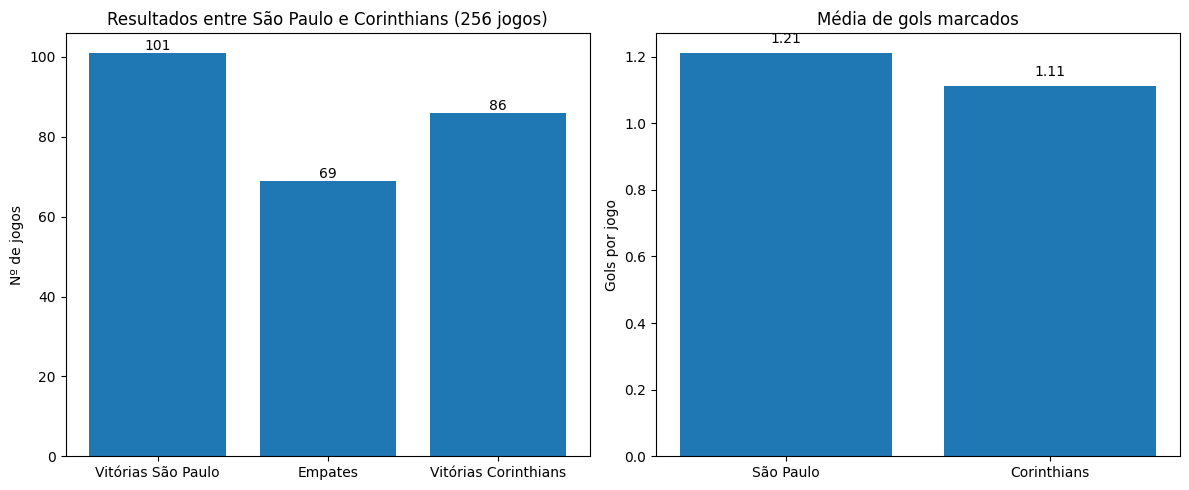

{'Jogos': 256, 'Vitórias São Paulo': 101, 'Vitórias Corinthians': 86, 'Empates': 69, 'Média gols São Paulo': 1.21, 'Média gols Corinthians': 1.11}


In [ ]:
res = rivalidades(df, "São Paulo", "Corinthians")
print(res)


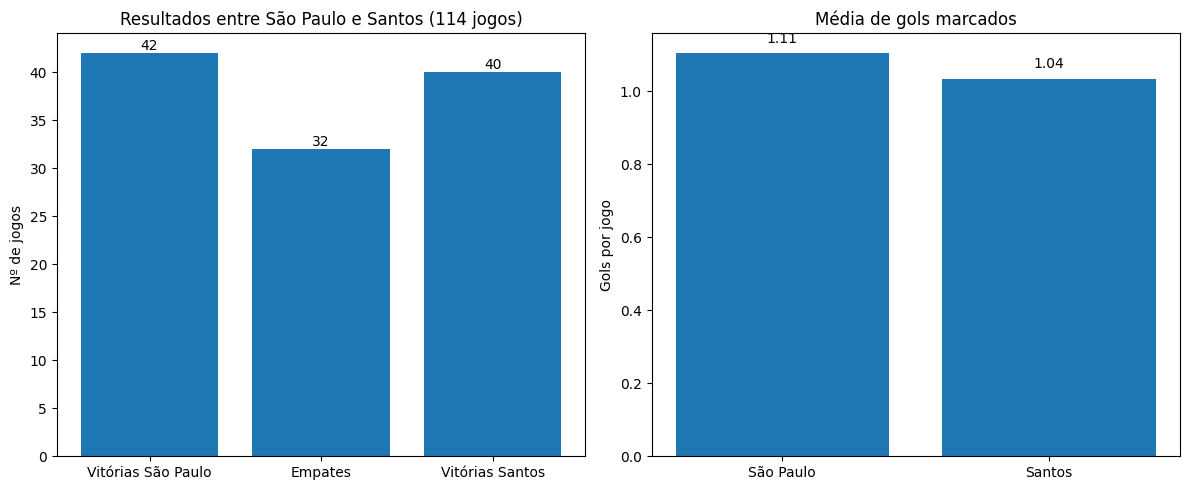

{'Jogos': 114, 'Vitórias São Paulo': 42, 'Vitórias Santos': 40, 'Empates': 32, 'Média gols São Paulo': 1.11, 'Média gols Santos': 1.04}


In [ ]:
res = rivalidades(df, "São Paulo", "Santos")
print(res)


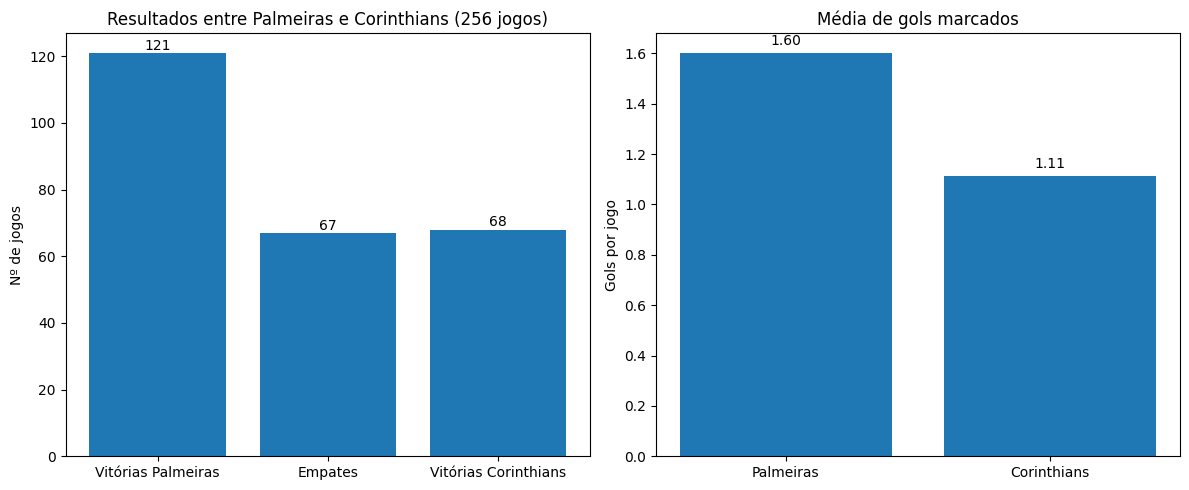

{'Jogos': 256, 'Vitórias Palmeiras': 121, 'Vitórias Corinthians': 68, 'Empates': 67, 'Média gols Palmeiras': 1.6, 'Média gols Corinthians': 1.11}


In [ ]:
res = rivalidades(df, "Palmeiras", "Corinthians")
print(res)

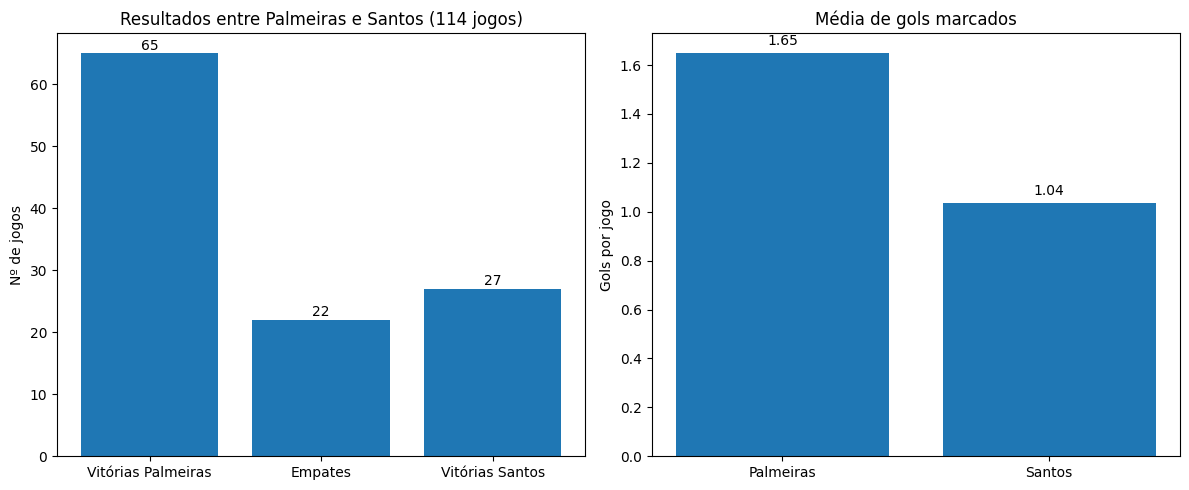

{'Jogos': 114, 'Vitórias Palmeiras': 65, 'Vitórias Santos': 27, 'Empates': 22, 'Média gols Palmeiras': 1.65, 'Média gols Santos': 1.04}


In [ ]:
res = rivalidades(df, "Palmeiras", "Santos")
print(res)

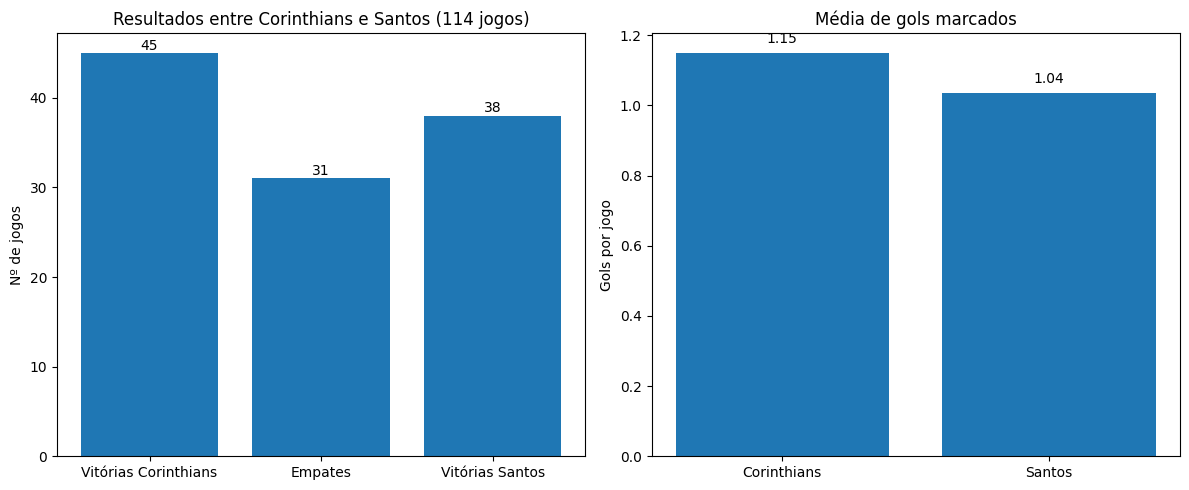

{'Jogos': 114, 'Vitórias Corinthians': 45, 'Vitórias Santos': 38, 'Empates': 31, 'Média gols Corinthians': 1.15, 'Média gols Santos': 1.04}


In [ ]:
res = rivalidades(df, "Corinthians", "Santos")
print(res)

### Times do Sul

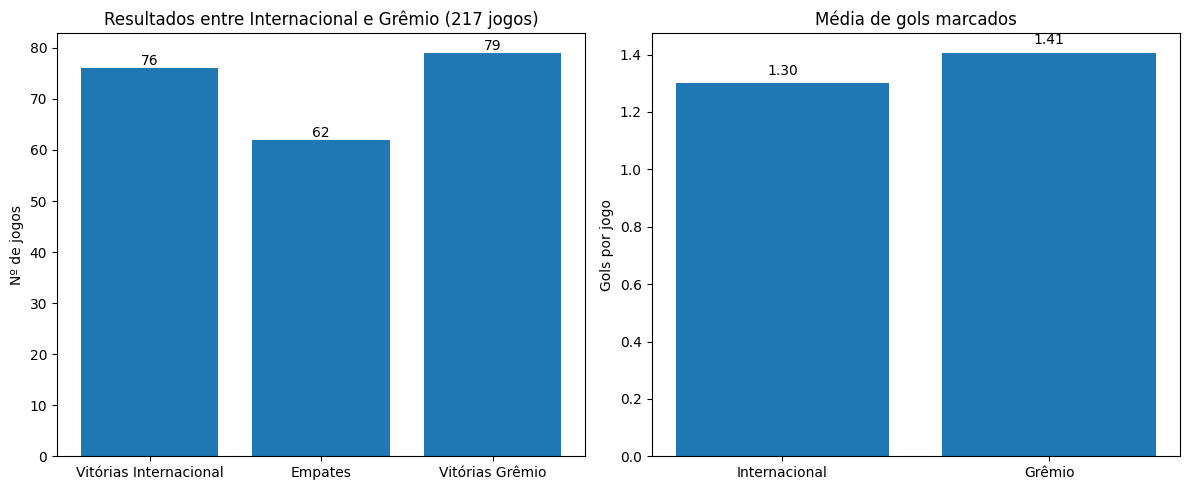

{'Jogos': 217, 'Vitórias Internacional': 76, 'Vitórias Grêmio': 79, 'Empates': 62, 'Média gols Internacional': 1.3, 'Média gols Grêmio': 1.41}


In [ ]:
res = rivalidades(df, "Internacional", "Grêmio")
print(res)

### Times do Rio de Janeiro

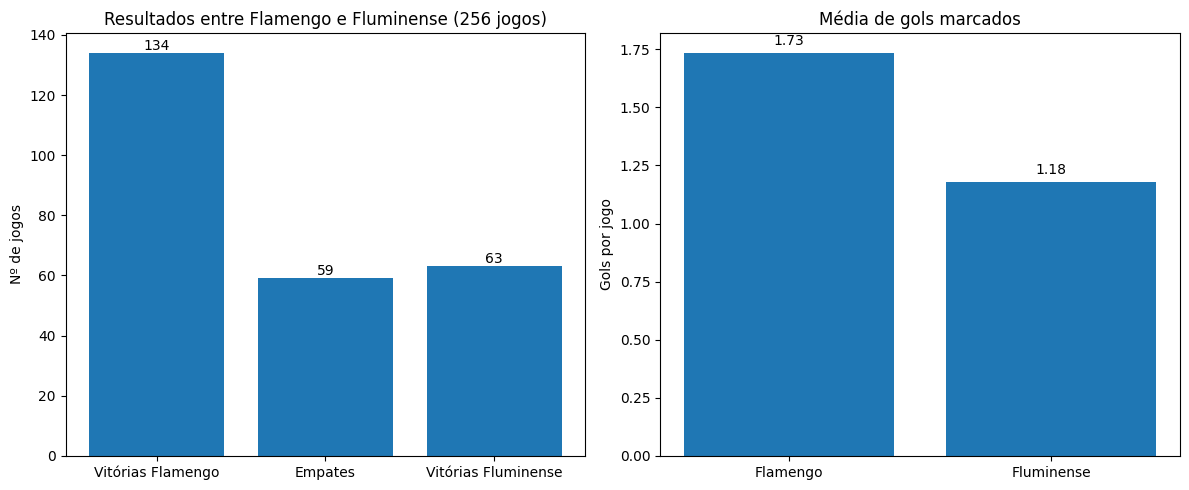

{'Jogos': 256, 'Vitórias Flamengo': 134, 'Vitórias Fluminense': 63, 'Empates': 59, 'Média gols Flamengo': 1.73, 'Média gols Fluminense': 1.18}


In [ ]:
res = rivalidades(df, "Flamengo", "Fluminense")
print(res)

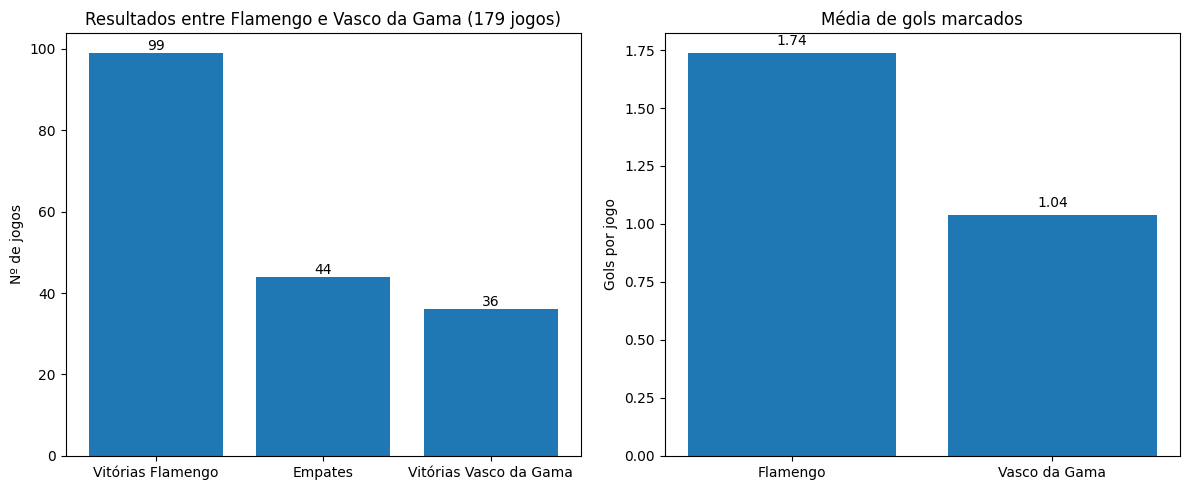

{'Jogos': 179, 'Vitórias Flamengo': 99, 'Vitórias Vasco da Gama': 36, 'Empates': 44, 'Média gols Flamengo': 1.74, 'Média gols Vasco da Gama': 1.04}


In [ ]:
res = rivalidades(df, "Flamengo", "Vasco da Gama")
print(res)

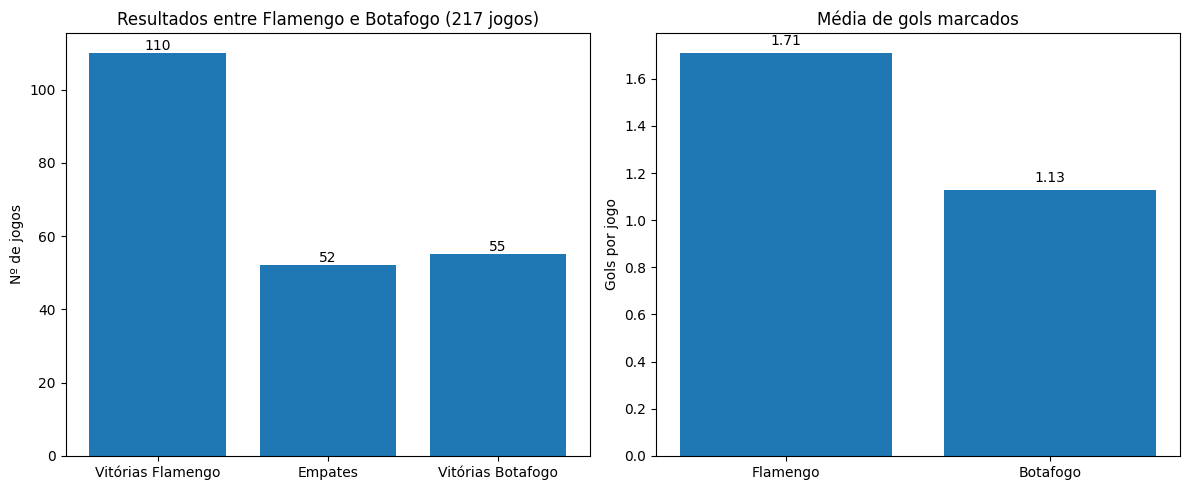

{'Jogos': 217, 'Vitórias Flamengo': 110, 'Vitórias Botafogo': 55, 'Empates': 52, 'Média gols Flamengo': 1.71, 'Média gols Botafogo': 1.13}


In [ ]:
res = rivalidades(df, "Flamengo", "Botafogo")
print(res)

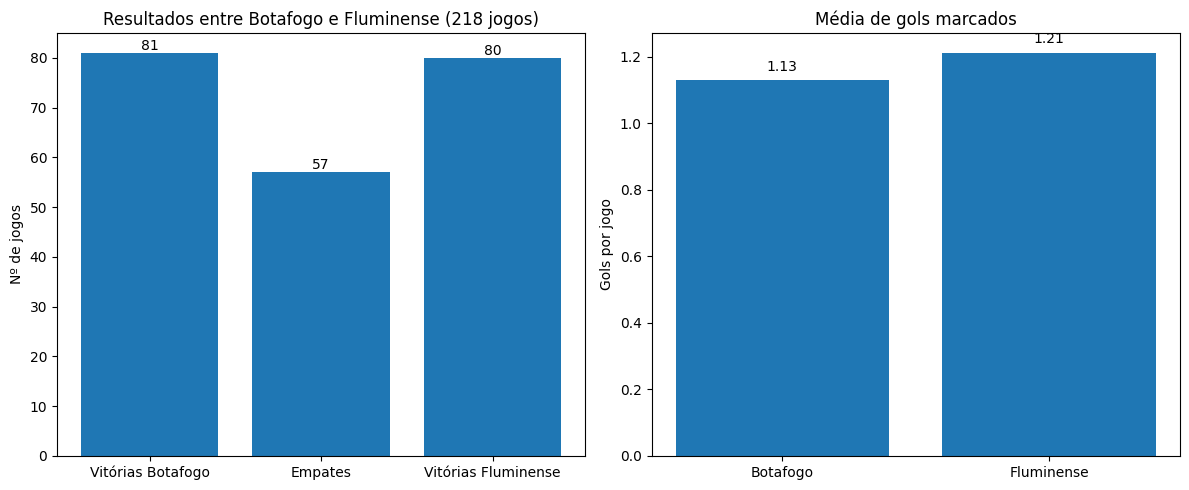

{'Jogos': 218, 'Vitórias Botafogo': 81, 'Vitórias Fluminense': 80, 'Empates': 57, 'Média gols Botafogo': 1.13, 'Média gols Fluminense': 1.21}


In [ ]:
res = rivalidades(df, "Botafogo", "Fluminense")
print(res)

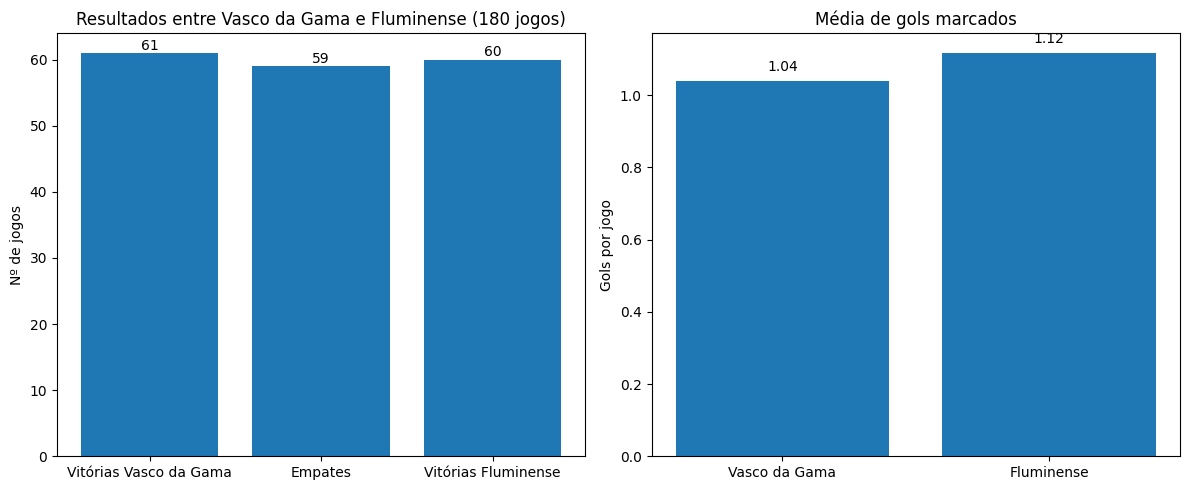

{'Jogos': 180, 'Vitórias Vasco da Gama': 61, 'Vitórias Fluminense': 60, 'Empates': 59, 'Média gols Vasco da Gama': 1.04, 'Média gols Fluminense': 1.12}


In [ ]:
res = rivalidades(df, "Vasco da Gama", "Fluminense")
print(res)

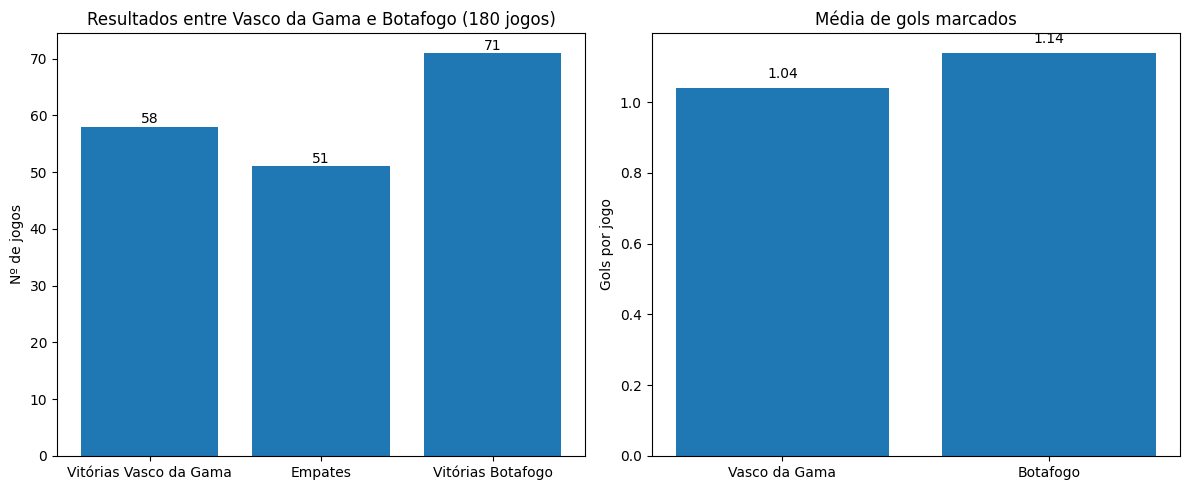

{'Jogos': 180, 'Vitórias Vasco da Gama': 58, 'Vitórias Botafogo': 71, 'Empates': 51, 'Média gols Vasco da Gama': 1.04, 'Média gols Botafogo': 1.14}


In [ ]:
res = rivalidades(df, "Vasco da Gama", "Botafogo")
print(res)

### Outros

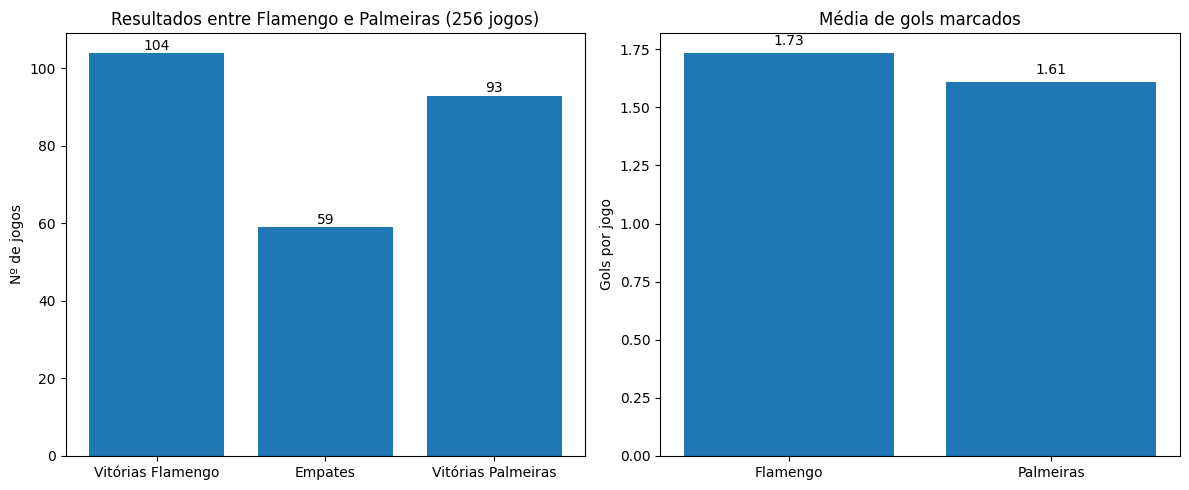

{'Jogos': 256, 'Vitórias Flamengo': 104, 'Vitórias Palmeiras': 93, 'Empates': 59, 'Média gols Flamengo': 1.73, 'Média gols Palmeiras': 1.61}


In [ ]:
res = rivalidades(df, "Flamengo", "Palmeiras")
print(res)

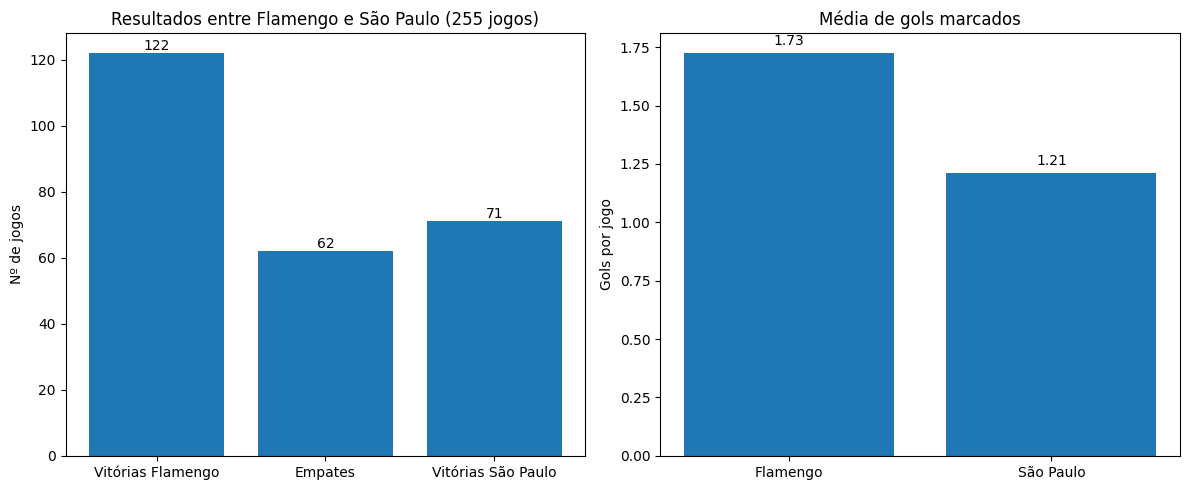

{'Jogos': 255, 'Vitórias Flamengo': 122, 'Vitórias São Paulo': 71, 'Empates': 62, 'Média gols Flamengo': 1.73, 'Média gols São Paulo': 1.21}


In [ ]:
res = rivalidades(df, "Flamengo", "São Paulo")
print(res)

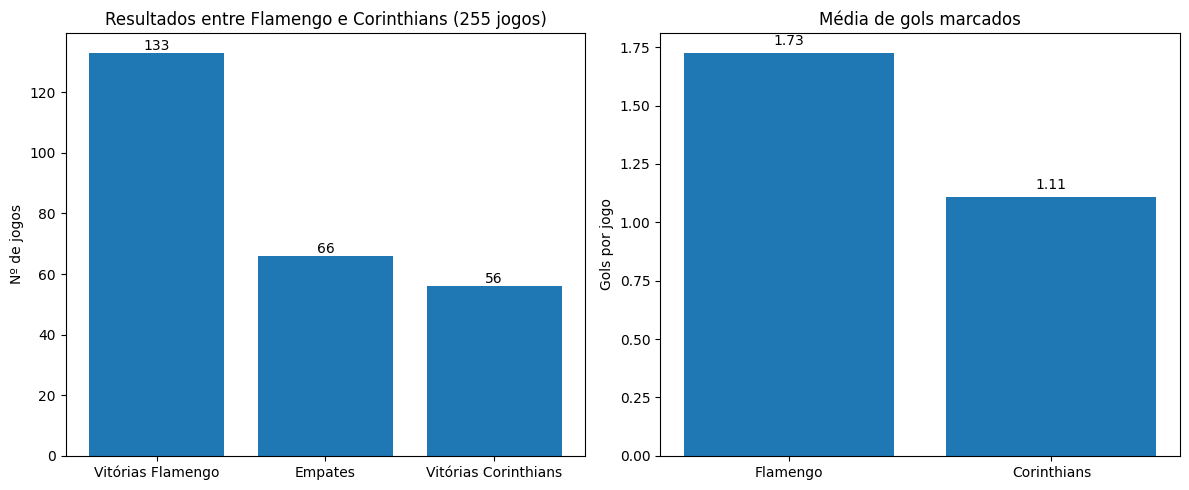

{'Jogos': 255, 'Vitórias Flamengo': 133, 'Vitórias Corinthians': 56, 'Empates': 66, 'Média gols Flamengo': 1.73, 'Média gols Corinthians': 1.11}


In [ ]:
res = rivalidades(df, "Flamengo", "Corinthians")
print(res)

## São Paulo

### Visão Geral Básica

1- Quais as estatísticas gerais do São Paulo nos anos de 2018 a 2024?

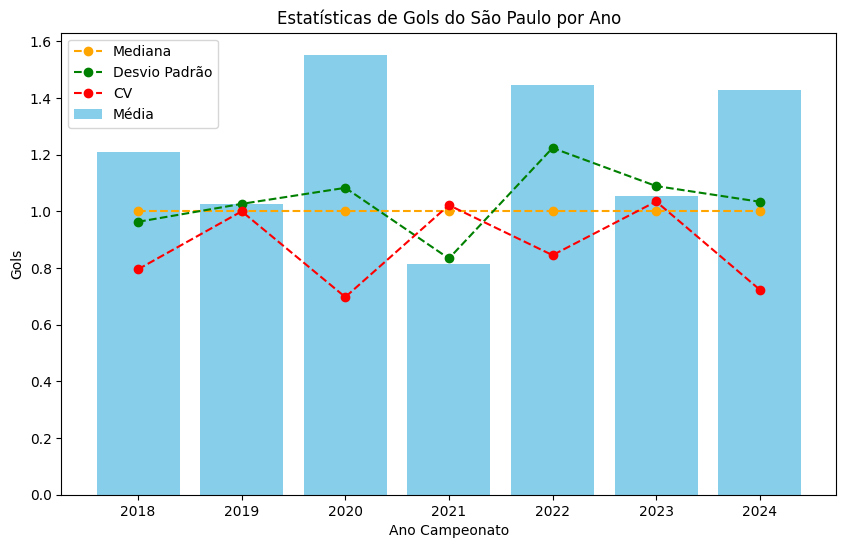

In [ ]:

# Agrupar por ano e calcular média, mediana, desvio padrão e CV
estatisticas_ano = df[df["time"] == "São Paulo"].groupby("ano_campeonato")["gols_pro"].agg(["mean", "median", "std"]).reset_index()
estatisticas_ano["cv"] = estatisticas_ano["std"] / estatisticas_ano["mean"]  # CV

plt.figure(figsize=(10,6))

plt.bar(estatisticas_ano["ano_campeonato"], estatisticas_ano["mean"], color="skyblue", label="Média")

# Linhas para mediana, desvio padrão e CV
plt.plot(estatisticas_ano["ano_campeonato"], estatisticas_ano["median"], color="orange", marker="o", linestyle="--", label="Mediana")
plt.plot(estatisticas_ano["ano_campeonato"], estatisticas_ano["std"], color="green", marker="o", linestyle="--", label="Desvio Padrão")
plt.plot(estatisticas_ano["ano_campeonato"], estatisticas_ano["cv"], color="red", marker="o", linestyle="--", label="CV")

plt.title("Estatísticas de Gols do São Paulo por Ano")
plt.xlabel("Ano Campeonato")
plt.ylabel("Gols")
plt.xticks(estatisticas_ano["ano_campeonato"])
plt.legend()
plt.show()


2- A média de gols é influênciada, se jogando como mandante ou visitante ?

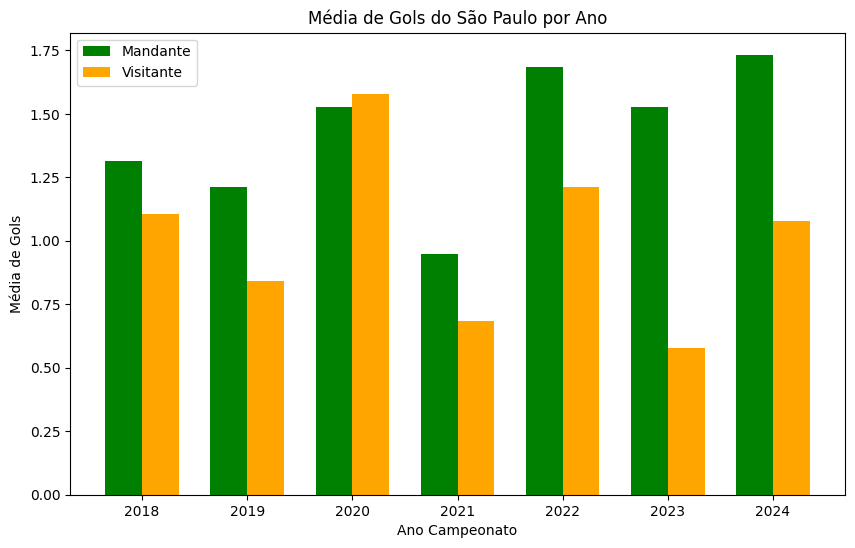

In [ ]:
frequencia = df[df['time'] == "São Paulo"].groupby('ano_campeonato').agg(
    mandante = ('gols_pro', lambda x: x[df.loc[x.index, 'local'] == 'casa'].mean()),
    visitante = ('gols_pro', lambda x: x[df.loc[x.index, 'local'] == 'fora'].mean())
).reset_index()

anos = frequencia['ano_campeonato']
x = np.arange(len(anos))
largura = 0.35

plt.figure(figsize=(10,6))

# Barras lado a lado
plt.bar(x - largura/2, frequencia["mandante"], width=largura, label="Mandante", color="green")
plt.bar(x + largura/2, frequencia["visitante"], width=largura, label="Visitante", color="orange")

plt.title("Média de Gols do São Paulo por Ano")
plt.xlabel("Ano Campeonato")
plt.ylabel("Média de Gols")
plt.xticks(x, anos)
plt.legend()
plt.show()

3- O time defende o mesmo tanto que ataca?

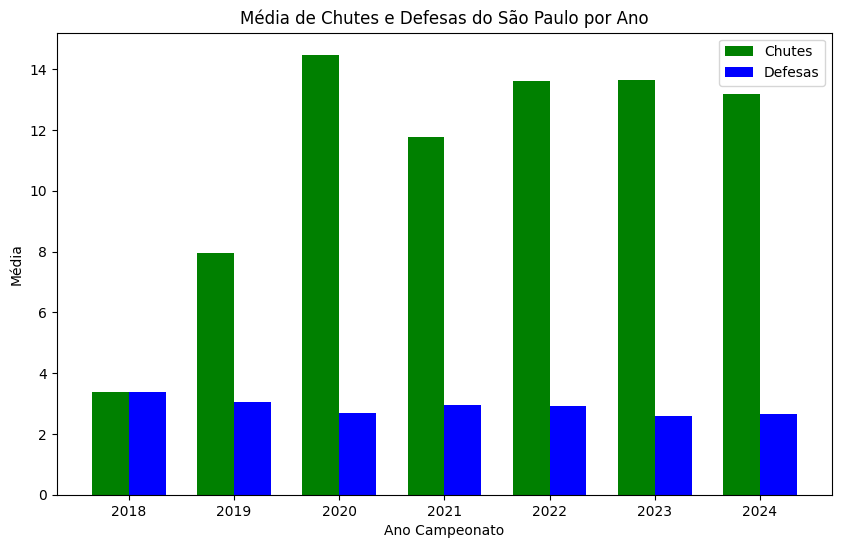

In [ ]:
tipos = df[df['time'] == 'São Paulo'].groupby('ano_campeonato').agg(
    chutes = ('chutes', 'mean'),
    defesas = ('defesas', 'mean'),
).reset_index()

anos = tipos['ano_campeonato']

x = np.arange(len(anos))
largura = 0.35

plt.figure(figsize=(10,6))

#barras lado a lado

plt.bar(x - largura/2, tipos["chutes"], width=largura, label="Chutes", color="green")

plt.bar(x + largura/2, tipos["defesas"], width=largura, label="Defesas", color="blue")


plt.title("Média de Chutes e Defesas do São Paulo por Ano")
plt.xlabel("Ano Campeonato")
plt.ylabel("Média")
plt.xticks(x, anos)
plt.legend()
plt.show()



4- O time possuí uma média de faltas e impedimentos alto?

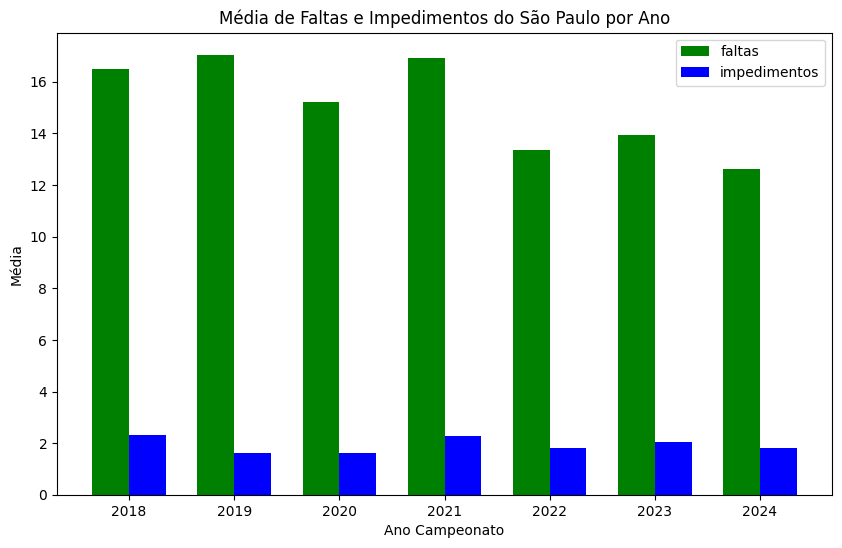

In [ ]:
tipos = df[df['time'] == 'São Paulo'].groupby('ano_campeonato').agg(
    faltas = ('faltas', 'mean'),
    impedimentos = ('impedimentos', 'mean'),
).reset_index()

anos = tipos['ano_campeonato']

x = np.arange(len(anos))
largura = 0.35

plt.figure(figsize=(10,6))

#barras lado a lado

plt.bar(x - largura/2, tipos["faltas"], width=largura, label="faltas", color="green")

plt.bar(x + largura/2, tipos["impedimentos"], width=largura, label="impedimentos", color="blue")


plt.title("Média de Faltas e Impedimentos do São Paulo por Ano")
plt.xlabel("Ano Campeonato")
plt.ylabel("Média")
plt.xticks(x, anos)
plt.legend()
plt.show()

5- Quantos pontos o São Paulo fez por temporada?

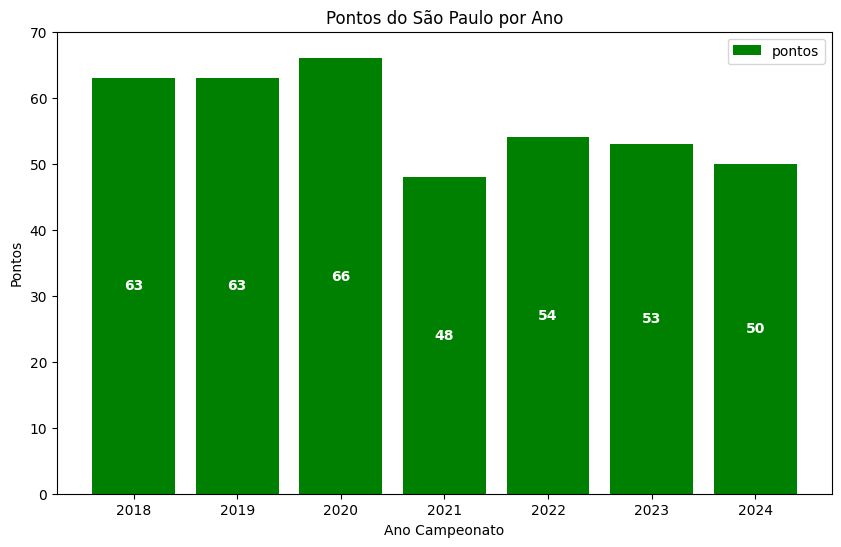

In [ ]:
pontos_ano = df[df['time'] == 'São Paulo'].groupby('ano_campeonato').agg(
    pontos = ('pontos', 'sum')
).reset_index()

plt.figure(figsize=(10,6))
anos = pontos_ano['ano_campeonato']

for i, ano in enumerate(anos):
    plt.text(ano, pontos_ano['pontos'][i]/2, str(pontos_ano['pontos'][i]), ha='center', va='center', color='white', fontweight='bold')


plt.bar(anos,  pontos_ano['pontos'], label="pontos", color="green")
plt.title('Pontos do São Paulo por Ano')
plt.xlabel('Ano Campeonato')
plt.ylabel('Pontos')
plt.xticks(anos)
plt.ylim(0,70)
plt.legend()
plt.show()

6- Quantos pontos o São Paulo faz sendo mandante e sendo visitante?

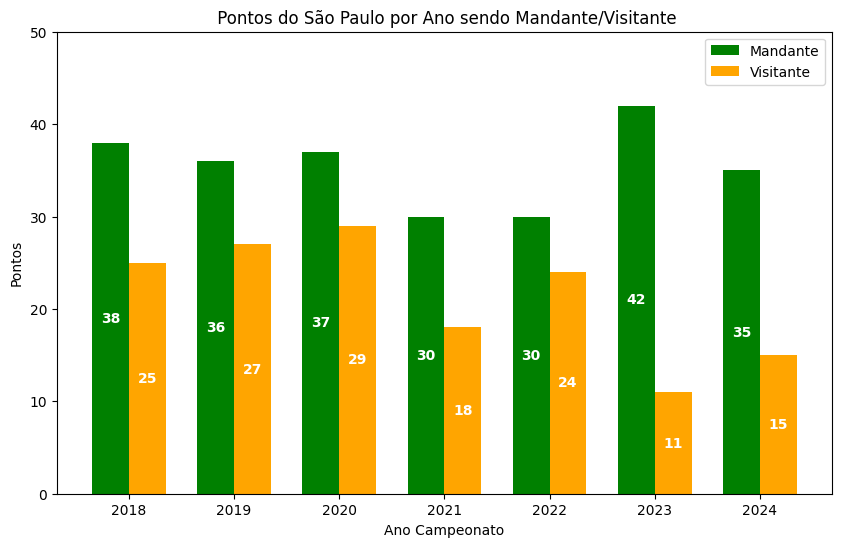

In [ ]:
pontos_onde = df[df['time'] == 'São Paulo'].groupby('ano_campeonato').agg(
    pontos_casa = ('pontos', lambda x: x[df.loc[x.index, 'local'] == 'casa'].sum()),
    pontos_fora = ('pontos', lambda x: x[df.loc[x.index, 'local'] == 'fora'].sum())
).reset_index()


anos = pontos_onde['ano_campeonato']
x = np.arange(len(anos))
largura = 0.35

plt.figure(figsize=(10,6))

# Barras lado a lado
plt.bar(x - largura/2, pontos_onde['pontos_casa'], width=largura, label="Mandante", color="green")
plt.bar(x + largura/2, pontos_onde['pontos_fora'], width=largura, label="Visitante", color="orange")

for i in range(len(anos)):
    plt.text(x[i] - largura/2, pontos_onde['pontos_casa'][i]/2, str(pontos_onde['pontos_casa'][i]), ha='center', va='center', color='white', fontweight='bold')
    plt.text(x[i] + largura/2, pontos_onde['pontos_fora'][i]/2, str(pontos_onde['pontos_fora'][i]), ha='center', va='center', color='white', fontweight='bold')

plt.title(" Pontos do São Paulo por Ano sendo Mandante/Visitante")
plt.xlabel("Ano Campeonato")
plt.ylabel("Pontos")
plt.xticks(x, anos)
plt.ylim(0,50)
plt.legend()
plt.show()

7- Qual o Desempenho do São Paulo nas temporadas de 2018 - 2024?

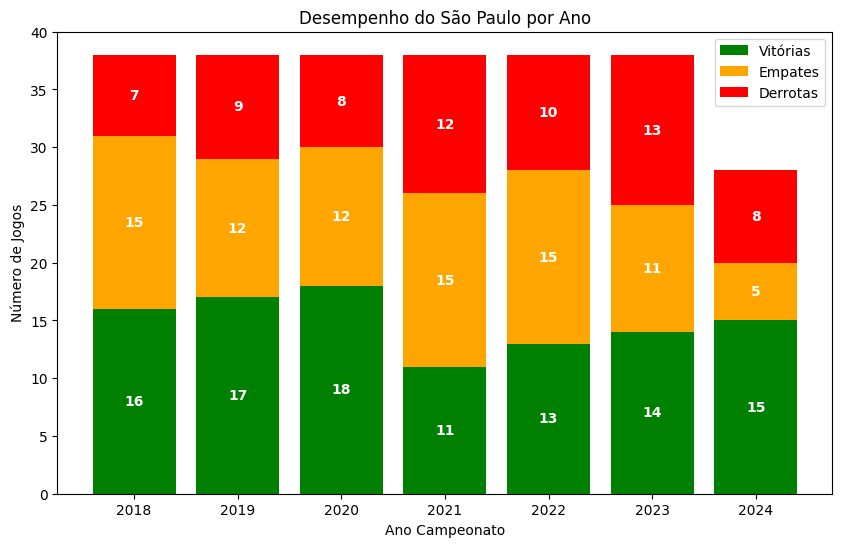

In [ ]:
resumo_temporada = df[df["time"] == "São Paulo"].groupby("ano_campeonato").agg(
    vitorias=("resultado", lambda x: (x==1).sum()),
    empates=("resultado", lambda x: (x==0).sum()),
    derrotas=("resultado", lambda x: (x==-1).sum()),
    pontos=("pontos","sum")
).reset_index()

# Criar figura
plt.figure(figsize=(10,6))

anos = resumo_temporada["ano_campeonato"]

# Barras
plt.bar(anos, resumo_temporada["vitorias"], label="Vitórias", color="green")
plt.bar(anos, resumo_temporada["empates"], bottom=resumo_temporada["vitorias"], label="Empates", color="orange")
plt.bar(anos, resumo_temporada["derrotas"], bottom=resumo_temporada["vitorias"] + resumo_temporada["empates"], label="Derrotas", color="red")

# Adicionar os números dentro das barras
for i, ano in enumerate(anos):

    plt.text(ano, resumo_temporada["vitorias"][i]/2, str(resumo_temporada["vitorias"][i]), ha='center', va='center', color='white', fontweight='bold')

    plt.text(ano, resumo_temporada["vitorias"][i] + resumo_temporada["empates"][i]/2, str(resumo_temporada["empates"][i]), ha='center', va='center', color='white', fontweight='bold')

    plt.text(ano, resumo_temporada["vitorias"][i] + resumo_temporada["empates"][i] + resumo_temporada["derrotas"][i]/2, str(resumo_temporada["derrotas"][i]), ha='center', va='center', color='white', fontweight='bold')

plt.title("Desempenho do São Paulo por Ano")
plt.xlabel("Ano Campeonato")
plt.ylabel("Número de Jogos")
plt.xticks(anos)
plt.ylim(0,40)
plt.legend()
plt.show()


8- A idade importa ?

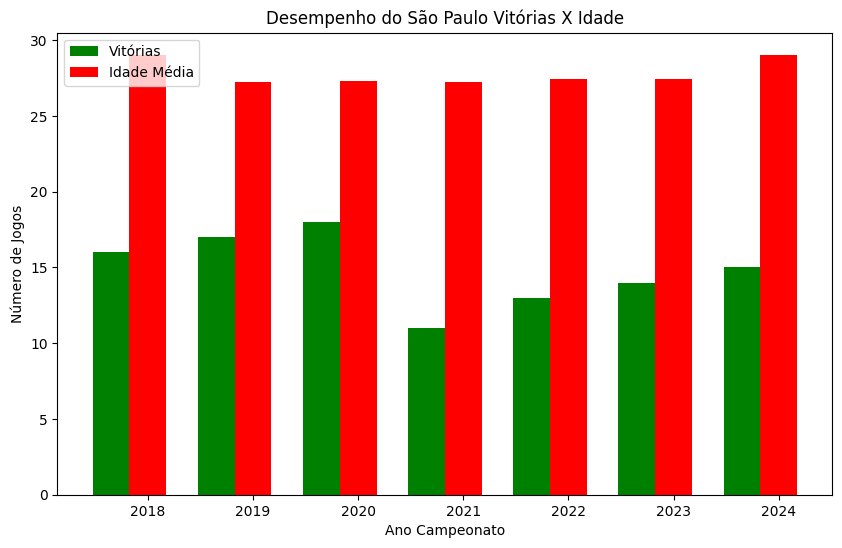

In [ ]:
estatisticas_ano = df[df["time"] == "São Paulo"].groupby("ano_campeonato").agg(
    vitorias=("resultado", lambda x: (x==1).sum()),
    idade = ("idade", "mean"),
)
anos = estatisticas_ano.index.tolist()

x = np.arange(len(anos))
largura = 0.35

plt.figure(figsize=(10,6))

plt.bar(x - largura, estatisticas_ano["vitorias"], width=largura, label="Vitórias", color="green")

plt.bar(x, estatisticas_ano["idade"], width=largura, label="Idade Média", color="red")


plt.title("Desempenho do São Paulo Vitórias X Idade")
plt.xlabel("Ano Campeonato")
plt.ylabel("Número de Jogos")
plt.xticks(x, anos)
plt.legend()
plt.show()


9- Desempenho de pontos do time pelas temporadas:

/tmp/ipython-input-356982731.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Ano")


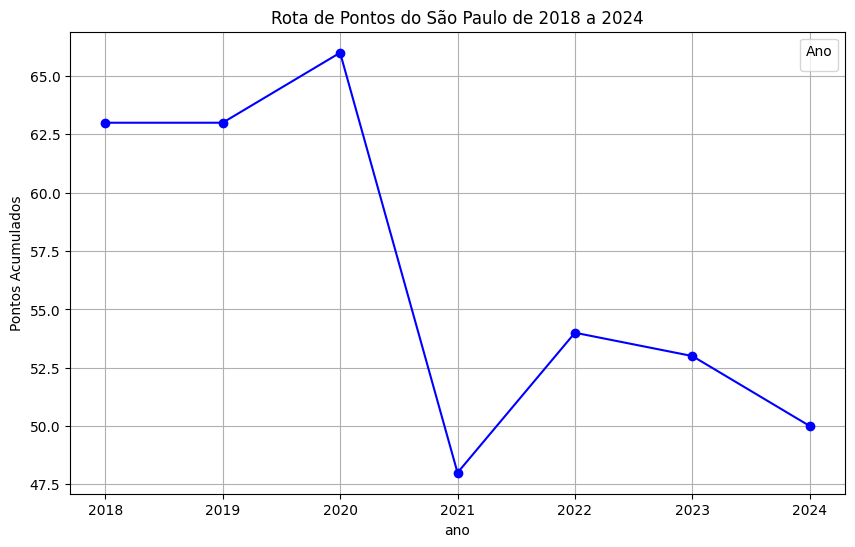

In [ ]:
estatisticas_ano = df[df["time"] == "São Paulo"].groupby("ano_campeonato").agg(
    pontos = ("pontos" , "sum")
)

anos = estatisticas_ano.index.tolist()

plt.figure(figsize=(10,6))

#gráfico de linhas

plt.plot(anos, estatisticas_ano["pontos"], marker='o', linestyle='-', color='blue')

plt.title("Rota de Pontos do São Paulo de 2018 a 2024")
plt.xlabel("ano")
plt.ylabel("Pontos Acumulados")
plt.legend(title="Ano")
plt.grid(True)
plt.show()

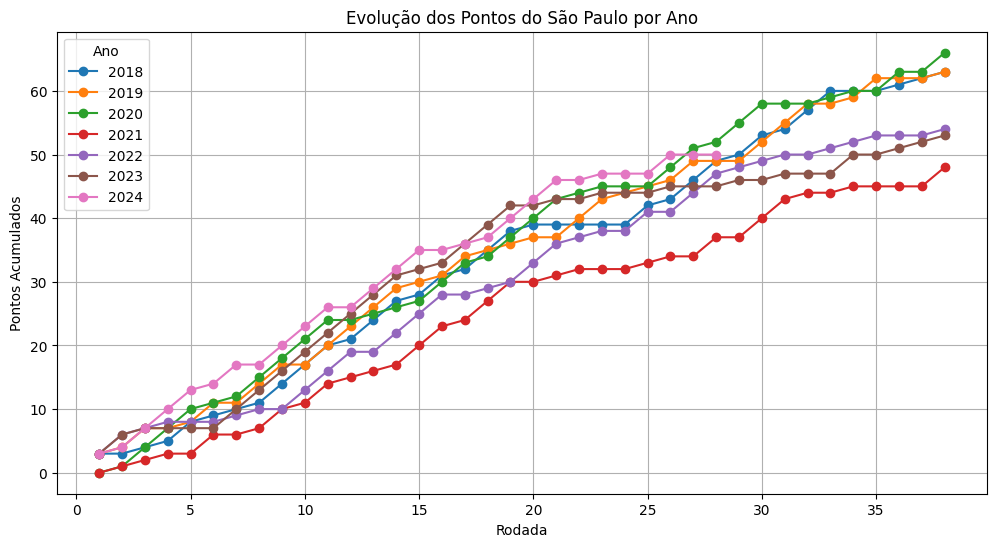

In [ ]:

df_sp = df[df["time"] == "São Paulo"].copy()


df_sp["pontos_acumulados"] = df_sp.groupby("ano_campeonato")["pontos"].cumsum()

plt.figure(figsize=(12,6))

# Criar uma linha para cada ano
for ano, dados in df_sp.groupby("ano_campeonato"):
    plt.plot(
        range(1, len(dados)+1),  # eixo X = rodadas (contagem)
        dados["pontos_acumulados"],
        marker='o', linestyle='-', label=str(ano)
    )

plt.title("Evolução dos Pontos do São Paulo por Ano")
plt.xlabel("Rodada")
plt.ylabel("Pontos Acumulados")
plt.legend(title="Ano")
plt.grid(True)
plt.show()

### Correlações

1- Existe correlação entre chutes, gols e pontos ?

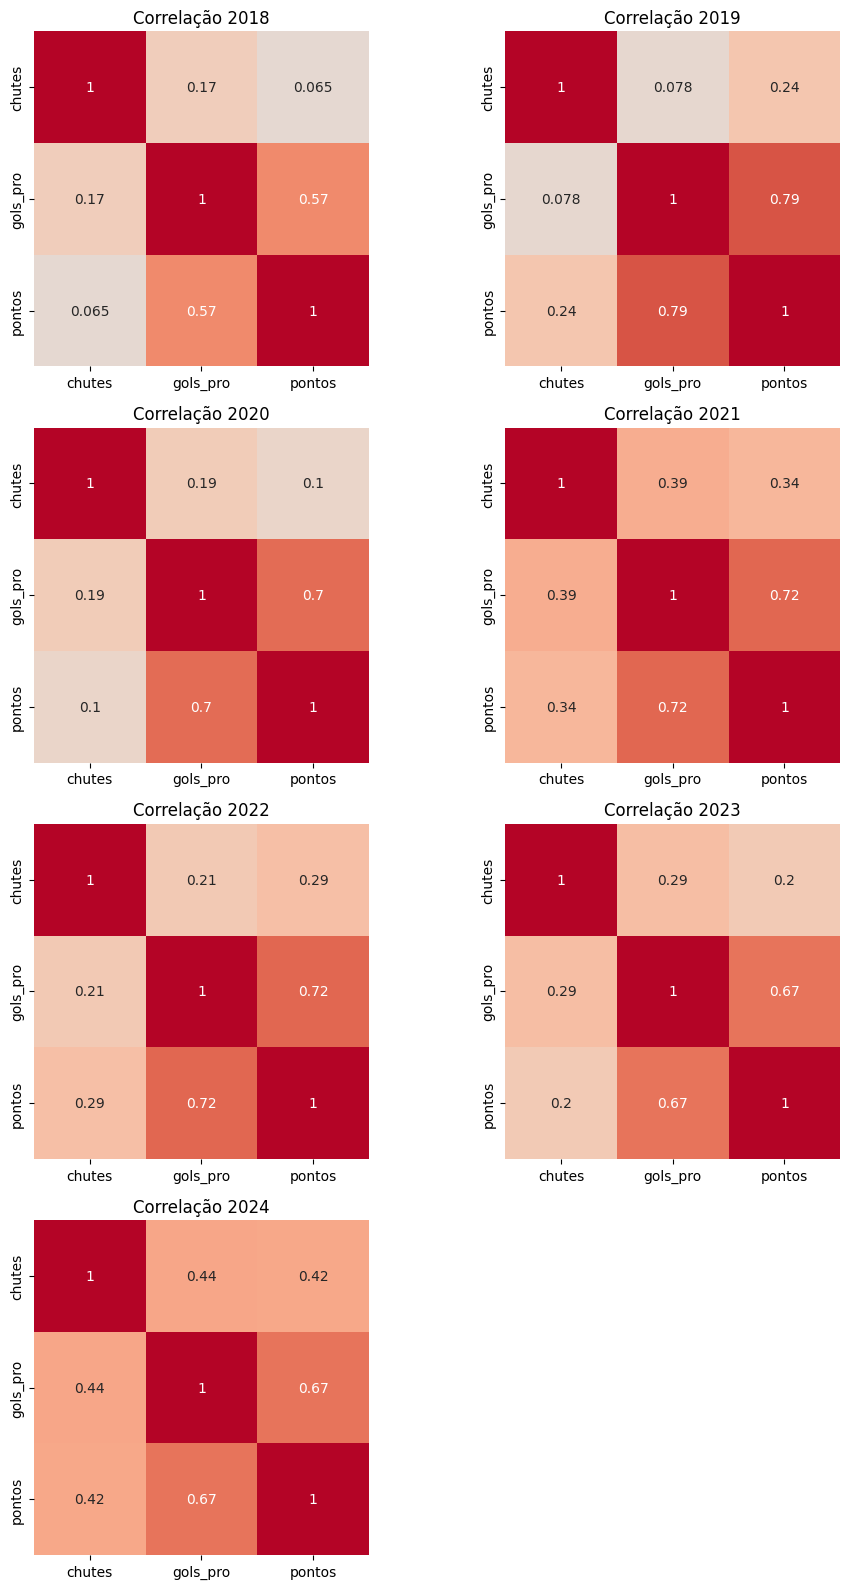

In [ ]:

df_sp = df[df["time"] == "São Paulo"]

anos = sorted(df_sp["ano_campeonato"].unique())

ncols = 2
nrows = math.ceil(len(anos) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 4*nrows))
axes = axes.flatten()

for i, ano in enumerate(anos):
    dados = df_sp[df_sp["ano_campeonato"] == ano]
    corr = dados[["chutes", "gols_pro", "pontos"]].corr()

    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
                square=True, ax=axes[i], cbar=False)
    axes[i].set_title(f"Correlação {ano}")


for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

2- Existe correlação para defesa ?

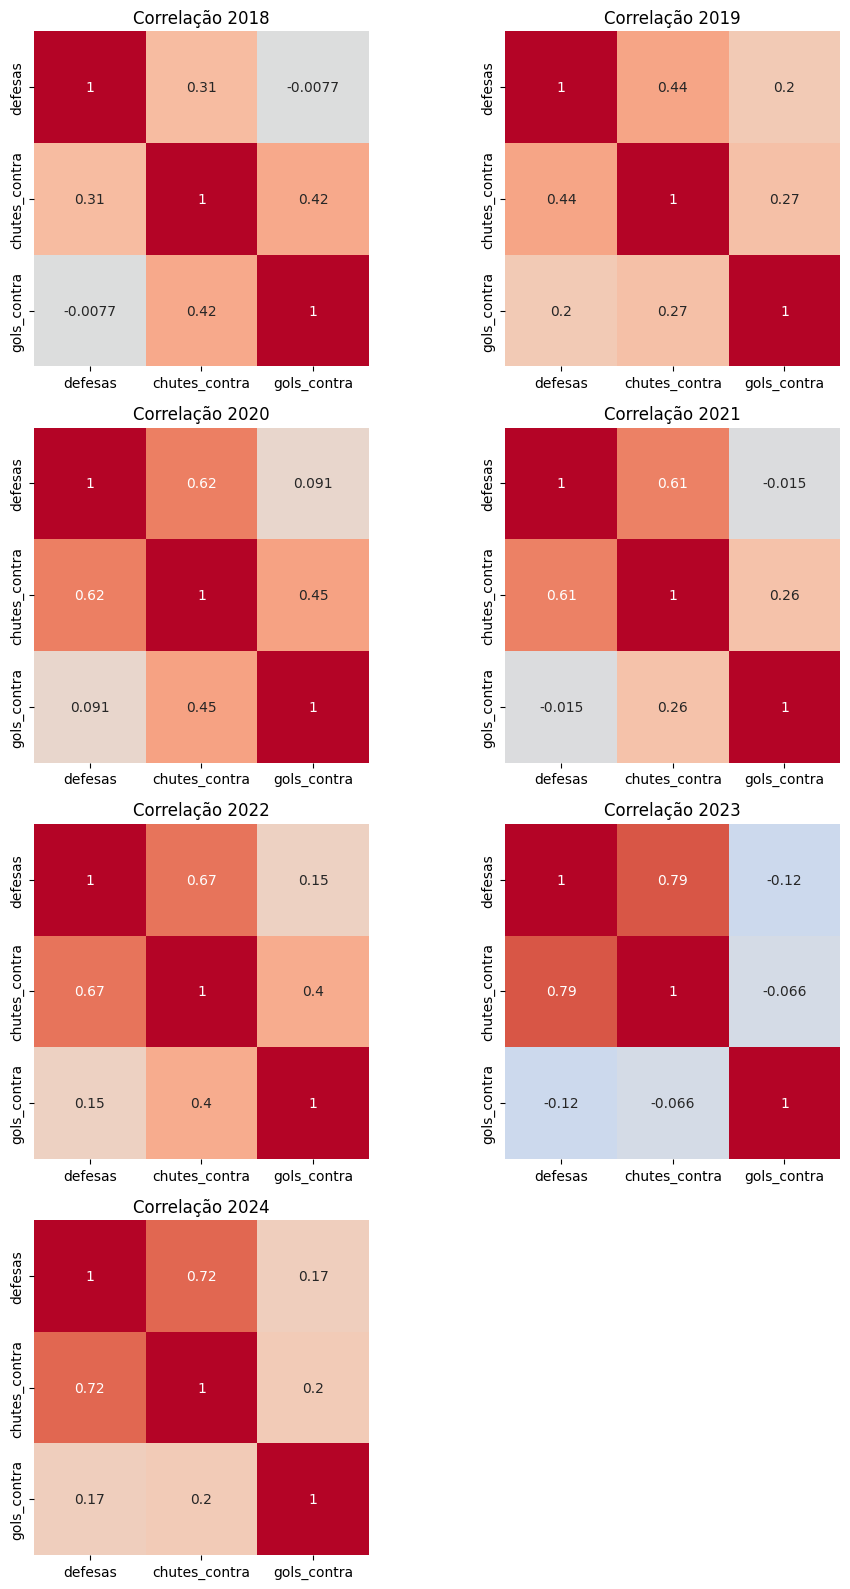

In [ ]:
# Filtra só o São Paulo
df_sp = df[df["time"] == "São Paulo"]

anos = sorted(df_sp["ano_campeonato"].unique())

ncols = 2
nrows = math.ceil(len(anos) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 4*nrows))
axes = axes.flatten()

for i, ano in enumerate(anos):
    dados = df_sp[df_sp["ano_campeonato"] == ano]
    corr = dados[["defesas", "chutes_contra", "gols_contra"]].corr()

    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
                square=True, ax=axes[i], cbar=False)
    axes[i].set_title(f"Correlação {ano}")


for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

3- Ánalise de outliers em váriaveis numéricas do São Paulo:

/tmp/ipython-input-2779866071.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


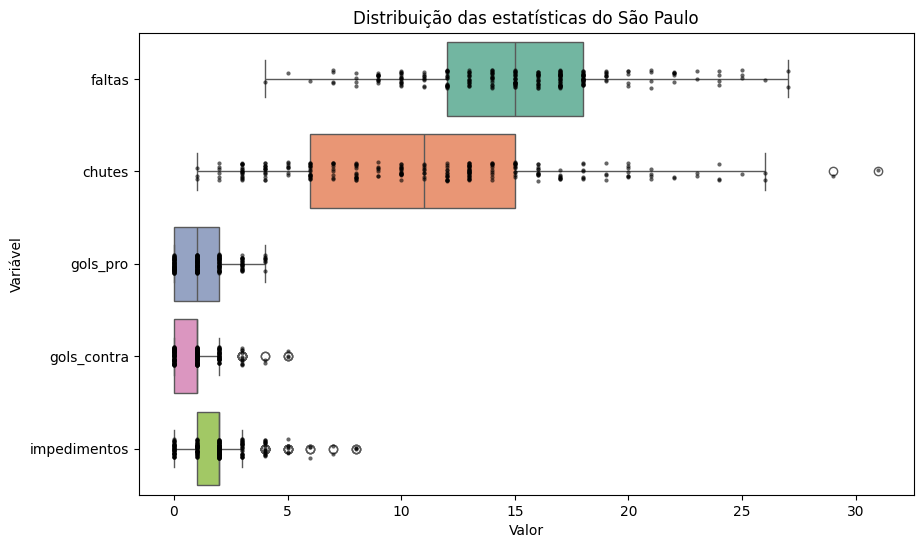

In [ ]:
# Filtra só o time desejado
time_escolhido = "São Paulo"
df_time = df[df["time"] == time_escolhido]


variaveis = ["faltas", "chutes", "gols_pro", "gols_contra", "impedimentos"]
df_melt = df_time[variaveis].melt(var_name="Variável", value_name="Valor")

plt.figure(figsize=(10,6))

# Boxplot horizontal
sns.boxplot(
    data=df_melt,
    y="Variável", x="Valor",
    orient="h", palette="Set2"
)

# Adiciona os pontos individuais (observações)
sns.stripplot(
    data=df_melt,
    y="Variável", x="Valor",
    orient="h", color="black", size=3, alpha=0.6
)

plt.title(f"Distribuição das estatísticas do {time_escolhido}")
plt.show()

## Classificação

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5126 entries, 0 to 5125
Data columns (total 49 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ano_campeonato                  5126 non-null   int64  
 1   data                            5126 non-null   object 
 2   rodada                          5126 non-null   int64  
 3   estadio                         5126 non-null   object 
 4   arbitro                         5126 non-null   object 
 5   publico                         5126 non-null   int64  
 6   publico_max                     5126 non-null   int64  
 7   time                            5126 non-null   object 
 8   time_visitante                  2563 non-null   object 
 9   tecnico_mandante                5126 non-null   object 
 10  tecnico_visitante               5126 non-null   object 
 11  colocacao_mandante              5126 non-null   int64  
 12  colocacao_visitante             51

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
classes = ["Vitória Visitante (-1)", "Empate (0)", "Vitória Mandante (1)"]

# alvo
y = df["resultado"]

# features (sem usar gols, porque senão o modelo vai copiar)
X = df[["colocacao_mandante","colocacao_visitante","valor_equipe_titular_mandante","valor_equipe_titular_visitante",
  "idade_media_titular_mandante","idade_media_titular_visitante","log_publico","log_publico_max"
]].copy()

# split estratificado (pra garantir que todas as classes aparecem no teste)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)  #  max_depth=2
model.fit(X_train, y_train)

y_pred = model.predict(X_test)


In [ ]:
y_pred = model.predict(X_test)

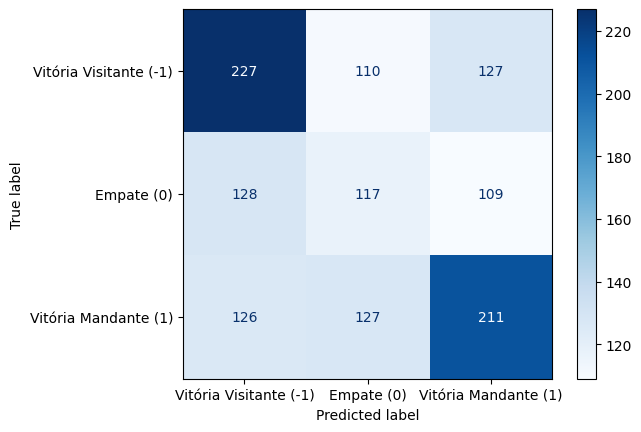

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap="Blues")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

# para multiclasse, precisa indicar o 'average'
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Acurácia: {accuracy:.2f}")
print(f"Precisão: {precision:.2f}")
print(f"Revocação: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")


Acurácia: 0.43
Precisão: 0.42
Revocação: 0.42
F1-Score: 0.42


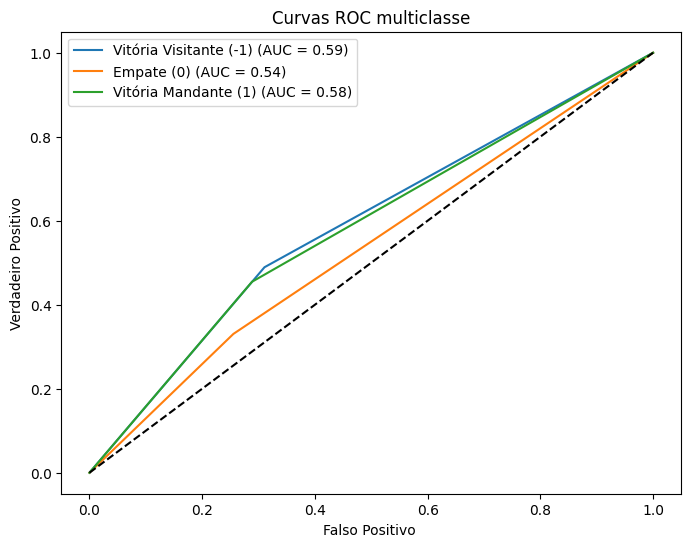

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# binariza o y_test (para multiclasse one-vs-rest)
y_bin = label_binarize(y_test, classes=[-1, 0, 1])
y_proba = model.predict_proba(X_test)

classes = ["Vitória Visitante (-1)", "Empate (0)", "Vitória Mandante (1)"]

plt.figure(figsize=(8,6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0,1],[0,1],"k--")
plt.xlabel("Falso Positivo ")
plt.ylabel("Verdadeiro Positivo")
plt.title("Curvas ROC multiclasse")
plt.legend()
plt.show()


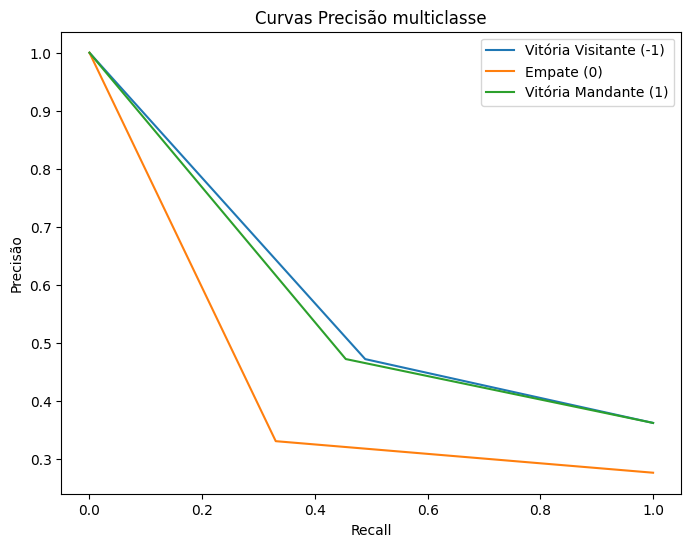

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))
for i, c in enumerate(classes):
    prec, rec, _ = precision_recall_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(rec, prec, label=f"{c}")

plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curvas Precisão multiclasse")
plt.legend()
plt.show()

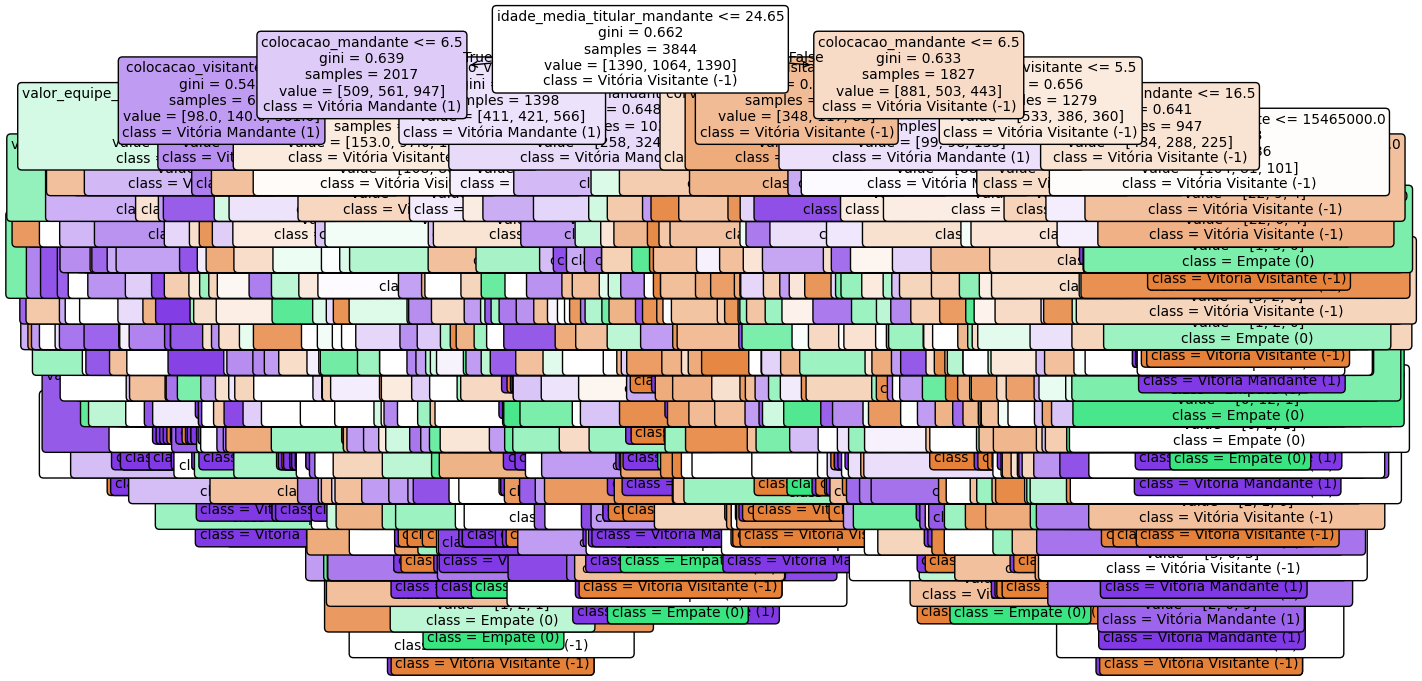

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=classes,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()


**Informações Extraídas: **

Acurácia 0.43 : este número significa que o modelo acertou 43% das partidas. Não é uma porcentagem muito boa, possivelmente pelo desbalanceamento das classe, porque como vimos nos gráficos, os times tem uma maior taxa de vitória sendo mandantes, o que pode acabar puxando o resultado.


**Matriz de Confusão: **

Com os resultados da matriz podemos ver que o modelo conseguiu prever bem as vitórias dos mandantes e dos visitantes, confundindo mais os empates onde o número de acertos (117) é quase o mesmo do de erros (128 + 109).

**Curvas Roc: **

Nas curvas os AUC ficaram entre 0,54 e 0,59. A melhor classe foi para vitória do visitante AUC = 0,59. Como o futebol é muito aleatório, podemos considerar que o modelo está conseguindo capturar alguns padrões reais.

**Curvas Precisão e Recall:**

A curva mostra que o modelo tem uma precisão alta no início, e decai arapidamente. Isso pode significar que ele acerta uma classe, mas deixa muitos casos errados, diminuindo assim o recall.


**Conclusões: **

O modelo não está muito bom, porém faz sentido já que o futebol é muito difícil de prever. Além disso, o moledo consegue ir melhor em vitórias do que empates, e a acurácia e as métricas no geral, estão até coerentes.

# Atividade 12/11


Trabalho do Quarto bimestre - Ciência de Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm
import seaborn as sns
import os
from google.colab import drive
import math


In [ ]:
# monta a base no google drive
drive.mount('drive')
meuDrive = os.path.join('drive', 'My Drive')

Mounted at drive


In [ ]:
# Ajuste para o seu caminho no drive!!!
database_path = os.path.join(meuDrive, 'BasesTrabalho')

# Nome do arquivo CSV dentro do dataset
file_path = os.path.join(database_path, 'df_fut.csv')

df_fut = pd.read_csv(file_path)


In [ ]:
#Feactures de resultados.

# colunas binárias
# Duas Colunas o time que venceu recebe 1, se o número de gols for igual os dois times ficam 0

df_fut["mandante_venceu"] = (df_fut["gols_mandante"] > df_fut["gols_visitante"]).astype(int)
df_fut["visitante_venceu"] = (df_fut["gols_visitante"] > df_fut["gols_mandante"]).astype(int)


# coluna única (3 categorias)
# Uma coluna, se o time mandante ganhou coluna recebe 1, se deu empate 0, e se o time visitante ganhou -1

df_fut["resultado"] = df_fut["gols_mandante"].sub(df_fut["gols_visitante"]).apply(
    lambda x: 1 if x > 0 else (-1 if x < 0 else 0)
)


In [ ]:
# Criar DataFrame para mandantes
mandante = df_fut.rename(columns={
    "time_mandante": "time",
    "gols_mandante": "gols_pro",
    "gols_visitante": "gols_contra",
    "chutes_mandante": "chutes",
    "chutes_visitante": "chutes_contra",
    "impedimentos_mandante": "impedimentos",
    "defesas_mandante": "defesas",
    "faltas_mandante": "faltas",
    "escanteios_mandante": "escanteios",
    "faltas_visitante": "faltas_contra",
    "idade_media_titular_mandante": "idade",
    "mandante_venceu": "vitoria",
    "visitante_venceu": "derrota",
}).copy()
mandante["local"] = "casa"

# Criar DataFrame para visitantes
visitante = df_fut.rename(columns={
    "time_visitante": "time",
    "gols_visitante": "gols_pro",
    "gols_mandante": "gols_contra",
    "chutes_visitante": "chutes",
    "chutes_mandante": "chutes_contra",
    "faltas_mandante": "faltas_contra",
    "impedimentos_visitante": "impedimentos",
    "defesas_visitante": "defesas",
    "escanteios_visitante": "escanteios",
    "faltas_visitante": "faltas",
    "idade_media_titular_visitante": "idade",
    "mandante_venceu": "derrota",
    "visitante_venceu": "vitoria",

}).copy()

visitante["local"] = "fora"

# Concatenar
df_concatenado = pd.concat([mandante, visitante], ignore_index=True)

# Feature de resultado (1 vitória, 0 empate, -1 derrota)
df_concatenado["resultado"] = df_concatenado["gols_pro"].sub(df_concatenado["gols_contra"]).apply(lambda x: 1 if x>0 else (-1 if x<0 else 0))

# Pontos (3 vitória, 1 empate, 0 derrota)
df_concatenado["pontos"] = df_concatenado["resultado"].apply(lambda x: 3 if x==1 else (1 if x==0 else 0))

df = df_concatenado

In [ ]:
# Criar coluna adversário a partir da rodada
df["adversario"] = df.groupby("rodada")["time"].transform(lambda x: x[::-1].values)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5126 entries, 0 to 5125
Data columns (total 49 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ano_campeonato                  5126 non-null   int64  
 1   data                            5126 non-null   object 
 2   rodada                          5126 non-null   int64  
 3   estadio                         5126 non-null   object 
 4   arbitro                         5126 non-null   object 
 5   publico                         5126 non-null   int64  
 6   publico_max                     5126 non-null   int64  
 7   time                            5126 non-null   object 
 8   time_visitante                  2563 non-null   object 
 9   tecnico_mandante                5126 non-null   object 
 10  tecnico_visitante               5126 non-null   object 
 11  colocacao_mandante              5126 non-null   int64  
 12  colocacao_visitante             51

In [ ]:
%%time
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


y = df["resultado"]


# 3. Selecionar features numéricas

X = df.select_dtypes(include=["int64", "float64"]).copy()

# Remove colunas da variável alvo caso estejam junto das numéricas
if "resultado" in X.columns:
    X = X.drop(columns=["resultado", "pontos", "derrota", "gols_pro", "gols_contra", "gols_1_tempo_mandante", "gols_1_tempo_visitante", "vitoria", "gols_partida"])



print("Dimensões originais:")
print("X:", X.shape)
print("y:", y.shape)


# 4.Divisão treino/teste

stratify_arg = y if len(np.unique(y)) > 1 else None

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=stratify_arg
)

print("\nDivisão feita:")
print("  Treino:", X_tr.shape, "Teste:", X_te.shape)
print("Classes únicas de y:", np.unique(y))


Dimensões originais:
X: (5126, 30)
y: (5126,)

Divisão feita:
  Treino: (3588, 30) Teste: (1538, 30)
Classes únicas de y: [-1  0  1]
CPU times: user 17.8 ms, sys: 13 µs, total: 17.8 ms
Wall time: 58.3 ms


Acurácia: 0.5312093628088427

Relatório de classificação:
               precision    recall  f1-score   support

          -1       0.54      0.70      0.61       556
           0       0.38      0.14      0.20       426
           1       0.55      0.67      0.61       556

    accuracy                           0.53      1538
   macro avg       0.49      0.50      0.47      1538
weighted avg       0.50      0.53      0.49      1538



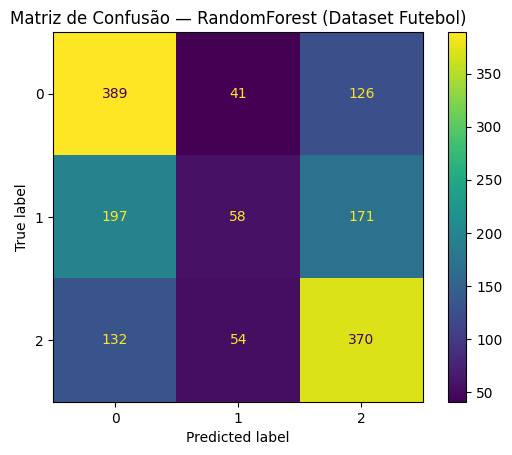

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt


# Treinamento do Random Forest
rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators=300
)
rf_model.fit(X_tr, y_tr)
y_pred = rf_model.predict(X_te)


# Métricas

print("Acurácia:", accuracy_score(y_te, y_pred))
print("\nRelatório de classificação:\n", classification_report(y_te, y_pred))


# Matriz de confusão

cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm).plot(values_format='d')

plt.title("Matriz de Confusão — RandomForest (Dataset Futebol)")
plt.show()


In [ ]:
%%time
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Grade de hiperparâmetros
param_grid = {
    'n_estimators': [200, 400, 800],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True],
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Treinamento do GridSearch
grid.fit(X_tr, y_tr)

# Resultados
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

print("\nMelhor média da validação cruzada (accuracy):")
print(grid.best_score_)

# Modelo otimizado
rf_best = grid.best_estimator_


Melhores parâmetros encontrados:
{'bootstrap': True, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Melhor média da validação cruzada (accuracy):
0.5136567949868495
CPU times: user 22.8 s, sys: 6.7 s, total: 29.5 s
Wall time: 1h 34min 49s


In [ ]:
# Extraindo resultados do GridSearch
res = pd.DataFrame(grid.cv_results_)

# Selecionando colunas úteis
cols = [
    c for c in res.columns
    if c.startswith('param_')
] + ['mean_test_score', 'mean_train_score', 'rank_test_score']

# Criando uma visualização ordenada
res_view = (
    res[cols]
    .sort_values(by='mean_test_score', ascending=False)
    .head(12)
    .reset_index(drop=True)
)

res_view


,param_bootstrap,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,mean_test_score,mean_train_score,rank_test_score
0,True,10,sqrt,2,5,200,0.513657,0.887403,1
1,True,20,log2,4,10,800,0.511705,0.939451,2
2,True,20,sqrt,1,10,200,0.511428,0.981396,3
3,True,None,sqrt,4,5,200,0.511153,0.956800,4
4,True,None,sqrt,4,2,200,0.511153,0.956800,4
5,True,None,sqrt,1,10,200,0.510033,0.982581,6
6,True,20,sqrt,1,10,400,0.509760,0.982859,7
7,True,None,log2,1,10,200,0.509754,0.980908,8
8,True,10,sqrt,2,2,400,0.509198,0.896113,9
9,True,None,sqrt,2,5,200,0.509197,0.996377,10


Acurácia em teste (melhor RF): 0.5260078023407022

Relatório de classificação:
               precision    recall  f1-score   support

          -1       0.53      0.72      0.61       556
           0       0.38      0.06      0.11       426
           1       0.54      0.68      0.60       556

    accuracy                           0.53      1538
   macro avg       0.48      0.49      0.44      1538
weighted avg       0.49      0.53      0.47      1538



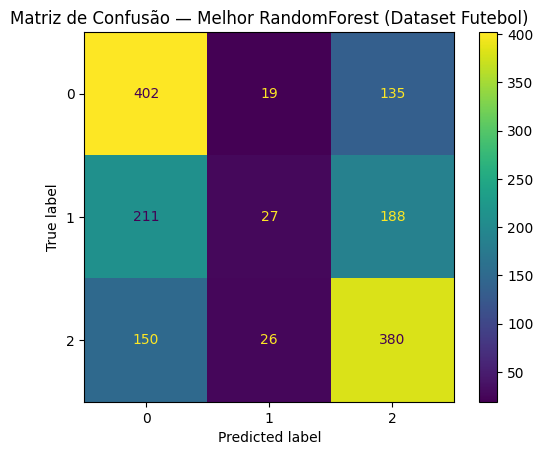

In [ ]:
# Predição com o melhor modelo encontrado no GridSearch
y_pred_best = rf_best.predict(X_te)

# Métricas de desempenho
print("Acurácia em teste (melhor RF):", accuracy_score(y_te, y_pred_best))
print("\nRelatório de classificação:\n", classification_report(y_te, y_pred_best))

# Matriz de confusão
cm_best = confusion_matrix(y_te, y_pred_best)
ConfusionMatrixDisplay(cm_best).plot(values_format='d')

plt.title("Matriz de Confusão — Melhor RandomForest (Dataset Futebol)")
plt.show()


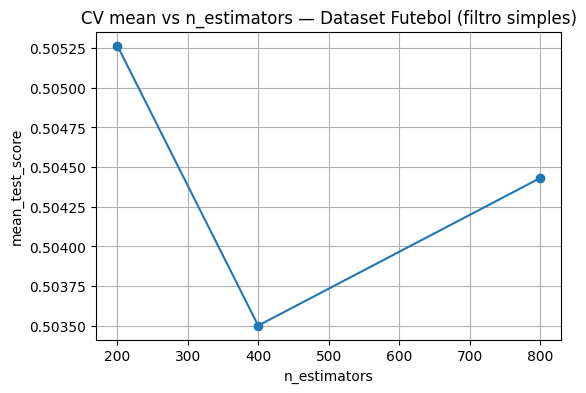

In [ ]:
# Filtrando combinações específicas dentro dos resultados do GridSearch
filt = (
    (res['param_max_depth'].isna()) &
    (res['param_bootstrap'] == True) &
    (res['param_max_features'] == 'sqrt')
)

subset = res[filt].copy()

if not subset.empty:
    # Agrupar por número de árvores e calcular média do CV
    agg = (
        subset
        .groupby('param_n_estimators')['mean_test_score']
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(6,4))
    plt.plot(agg['param_n_estimators'], agg['mean_test_score'], marker='o')

    plt.title("CV mean vs n_estimators — Dataset Futebol (filtro simples)")
    plt.xlabel("n_estimators")
    plt.ylabel("mean_test_score")
    plt.grid(True)
    plt.show()

else:
    print("Nenhuma combinação atende ao filtro proposto para a visualização.")


In [ ]:
# Importâncias extraídas do melhor modelo encontrado via GridSearch
importances = rf_best.feature_importances_

# Usar diretamente os nomes das colunas do seu DataFrame
feat_names = list(X.columns)

# Montar DataFrame ordenado por importância
imp_df = pd.DataFrame({
    'feature': feat_names,
    'importance': importances
}).sort_values('importance', ascending=False).reset_index(drop=True)

# Exibir top 20
imp_df.head(20)


,feature,importance
0,colocacao_mandante,0.068865
1,valor_equipe_titular_visitante,0.066761
2,valor_equipe_titular_mandante,0.061874
3,colocacao_visitante,0.057222
4,idade,0.042319
5,rodada,0.037827
6,chutes_contra,0.037691
7,idade_media_titular_mandante,0.036761
8,chutes,0.036437
9,log_publico,0.034475


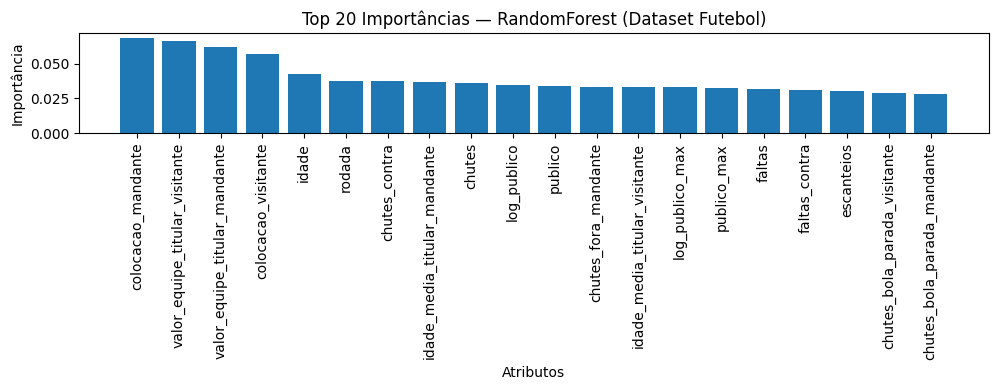

In [ ]:
topk = min(20, len(imp_df))

plt.figure(figsize=(10,4))
plt.bar(range(topk), imp_df['importance'][:topk])

plt.xticks(range(topk), imp_df['feature'][:topk], rotation=90)
plt.title(f"Top {topk} Importâncias — RandomForest (Dataset Futebol)")
plt.xlabel("Atributos")
plt.ylabel("Importância")

plt.tight_layout()
plt.show()


In [ ]:
import joblib

# Nome do arquivo do modelo — adaptado para o seu dataset
model_path = "rf_dataset_futebol_best.joblib"

# Salvar o melhor modelo do Grid Search
joblib.dump(rf_best, model_path)
print("Modelo salvo em:", model_path)

# Carregar o modelo salvo
loaded = joblib.load(model_path)

# Validar modelo carregado
print("Acurácia (modelo carregado):", loaded.score(X_te, y_te))

# Exemplo de uso em produção:
# preds = loaded.predict(novo_X)


Modelo salvo em: rf_dataset_futebol_best.joblib
Acurácia (modelo carregado): 0.5260078023407022


# Atividade Pycaret 26/11

In [ ]:
# Esta célula é pensada para Google Colab e ambientes limpos.
# Execute UMA vez e depois reinicie o runtime.
# No Colab: Menu -> Runtime -> Restart runtime

!pip install --upgrade pip
!pip install git+https://github.com/pycaret/pycaret.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.3 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Cloning https://github.com/pycaret/pycaret.git to /tmp/pip-req-build-xn_tpiat
  Running command git clone --filter=blob:none --quiet https://github.com/pycaret/pycaret.git /tmp/pip-req-build-xn_tpiat
  Resolved https://github.com/pycaret/pycaret.git to commit 58ec3c282d58e94727f9d5b77b49f241e9103ab3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of category-encoders to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of pmdarima

In [ ]:
import sys
import platform

import numpy as np
import pandas as pd
import plotly.express as px

from sklearn.datasets import load_iris, load_wine, load_digits, fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import pycaret
from pycaret.classification import (
    setup,
    compare_models,
    plot_model,
    evaluate_model,
    predict_model,
    save_model,
    load_model,
)

print("Versão do Python:", sys.version)
print("Sistema:", platform.platform())
print("Versão do PyCaret:", pycaret.__version__)

Versão do Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Sistema: Linux-6.6.105+-x86_64-with-glibc2.35
Versão do PyCaret: 3.4.0


Carregando múltiplas bases (Iris, Wine, Digits, Covertype)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# %%time
# ---- Base Escolhida (usada apenas para impressão) ----
base_escolhida = "df_fut"

# target (y)
y = df_fut["resultado"]

# features (X): Mantendo a lógica de selecionar apenas as colunas que você quer usar
# X = df_fut.drop(columns=["resultado"]).copy()

# Remove colunas que não podem ser features ou causam vazamento de dados:
cols_to_drop = ["resultado", "pontos", "derrota", "gols_pro", "gols_contra", "gols_1_tempo_mandante", "gols_1_tempo_visitante", "vitoria", "gols_partida"]
# Você também pode querer dropar colunas que estavam no seu X anterior, se necessário.
# Exemplo: X = X.drop(columns=[...], errors='ignore')
X = X.drop(columns=cols_to_drop, errors='ignore')


# Divisão treino/teste (útil se quiser avaliar manualmente com sklearn)
X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y if len(np.unique(y)) > 1 else None,
)

print(f"\nBase selecionada: {base_escolhida.upper()}")
print("Dimensões completas:")
print("  X:", X.shape, "y:", y.shape)
print("  Treino:", X_tr.shape, "Teste:", X_te.shape)
print("Classes únicas:", np.unique(y))

# ---- Criar DataFrame 'data' para uso com PyCaret ----

# A CORREÇÃO PRINCIPAL: Juntar os DataFrames Pandas X e y de volta
# Isso garante que os nomes das colunas e os dados estejam perfeitamente alinhados.
data = X.copy()
data["target"] = y.values # Anexamos a Série 'y' como nova coluna 'target'

target_col = "target"

print("\nDataFrame para PyCaret (Dataframe Completo para o setup):")
print(data.head())


Base selecionada: DF_FUT
Dimensões completas:
  X: (2563, 35) y: (2563,)
  Treino: (1794, 35) Teste: (769, 35)
Classes únicas: [-1  0  1]

DataFrame para PyCaret (Dataframe Completo para o setup):
   ano_campeonato        data  rodada                             estadio  \
0            2018  2018-10-06      28                    Arena da Baixada   
1            2018  2018-10-02      27      Estádio Durival Britto e Silva   
2            2018  2018-08-23      20      Estádio Durival Britto e Silva   
3            2018  2018-11-18      35     Estádio Cícero Pompeu de Toledo   
4            2018  2018-10-30      31  Estádio Governador Plácido Castelo   

                          arbitro  publico  publico_max time_mandante  \
0                   Raphael Claus    11443        42372   Atlético-PR   
1       Flavio Rodrigues de Souza     3894        20083        Paraná   
2  Péricles Bassols Pegado Cortez     8561        20083        Paraná   
3                     Héber Lopes    14058     

In [ ]:
# Distribuição das classes
class_counts = data[target_col].value_counts().sort_index()

print("Distribuição das classes:")
print(class_counts)

# Transformar em DataFrame para o Plotly
df_classes = class_counts.reset_index()
df_classes.columns = [target_col, "count"]  # renomeia corretamente

# Gráfico de barras
fig_bar = px.bar(
    df_classes,
    x=target_col,
    y="count",
    title=f"Distribuição da variável alvo (base: {base_escolhida})",
    labels={target_col: "Classe", "count": "Contagem"},
)
fig_bar.show()

Distribuição das classes:
target
-1     637
 0     709
 1    1217
Name: count, dtype: int64


In [ ]:
# Escolher colunas específicas que sabemos serem numéricas (e úteis)
col_x = 'log_publico'
col_y = 'log_publico_max'

# Garante que as colunas existam no DataFrame antes de plotar
if col_x in data.columns and col_y in data.columns:

    # Gráfico de Dispersão (Scatter Plot)
    fig_scatter = px.scatter(
        data,
        x=col_x,
        y=col_y,
        color='target', # Usa a coluna 'target' para colorir os pontos
        title=f'{col_x} vs {col_y} (colorido por classe) - {base_escolhida}',
        opacity=0.7,
    )
    fig_scatter.show()

elif col_x in data.columns:
    # Caso col_y não exista, mostra apenas o histograma de col_x (Fallback)
    fig_hist = px.histogram(
        data,
        x=col_x,
        color='target',
        barmode='overlay',
        nbins=40,
        title=f'Distribuição de {col_x} por classe - {base_escolhida}',
    )
    fig_hist.show()
else:
    print("As colunas 'log_publico' e 'log_publico_max' não foram encontradas no DataFrame.")

In [ ]:
clf_setup = setup(
    data=data,
    target=target_col,
    session_id=42,
    normalize=True,
    verbose=True,
)

clf_setup

,Description,Value
0,Session id,42
1,Target,target
2,Target type,Multiclass
3,Target mapping,"-1: 0, 0: 1, 1: 2"
4,Original data shape,"(2563, 36)"
5,Transformed data shape,"(2563, 36)"
6,Transformed train set shape,"(1794, 36)"
7,Transformed test set shape,"(769, 36)"
8,Numeric features,28
9,Categorical features,7


In [ ]:
best_clf = compare_models()

best_clf

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.1720
dt,Decision Tree Classifier,0.9972,0.9979,0.9972,0.9973,0.9972,0.9956,0.9956,0.4640
lightgbm,Light Gradient Boosting Machine,0.9944,0.9990,0.9944,0.9946,0.9944,0.9912,0.9913,1.8550
gbc,Gradient Boosting Classifier,0.9939,0.0000,0.9939,0.9940,0.9938,0.9903,0.9904,3.3360
xgboost,Extreme Gradient Boosting,0.9939,0.9998,0.9939,0.9940,0.9938,0.9903,0.9904,0.5580
svm,SVM - Linear Kernel,0.9766,0.0000,0.9766,0.9778,0.9765,0.9631,0.9637,0.2700
qda,Quadratic Discriminant Analysis,0.9705,0.0000,0.9705,0.9707,0.9703,0.9534,0.9537,0.2510
rf,Random Forest Classifier,0.8968,0.9818,0.8968,0.8989,0.8956,0.8358,0.8380,1.1560
et,Extra Trees Classifier,0.8723,0.9686,0.8723,0.8753,0.8681,0.7949,0.8006,0.4830
lda,Linear Discriminant Analysis,0.8305,0.0000,0.8305,0.8746,0.8361,0.7377,0.7535,0.1510


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=1000,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=42, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

Avaliando o modelo

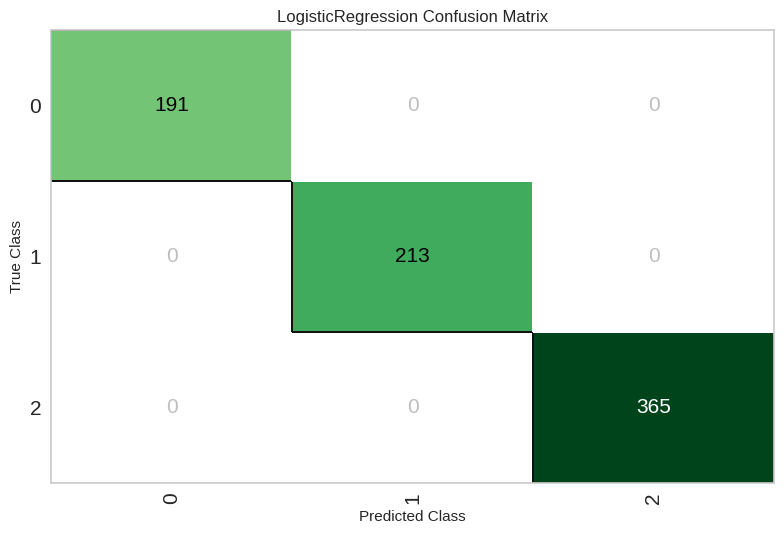

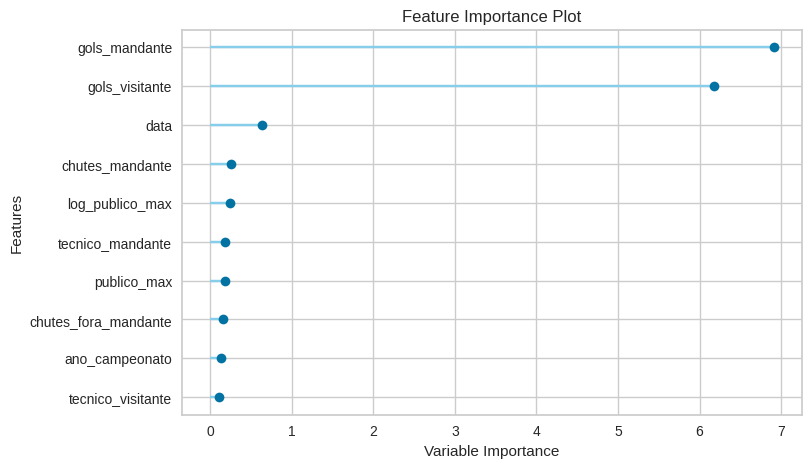

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [ ]:
# Matriz de confusão
plot_model(best_clf, plot='confusion_matrix')

# Importância das variáveis (features)
plot_model(best_clf, plot='feature')

# Painel interativo de avaliação
evaluate_model(best_clf)

Predizendo em novos dados

In [ ]:
# "Novos dados": usamos o próprio dataset, mas sem a coluna alvo
data_unseen = data.drop(columns=[target_col])

predictions = predict_model(best_clf, data=data_unseen)

predictions.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante,log_publico,log_publico_max,prediction_label,prediction_score
0,2018,2018-10-06,28,Arena da Baixada,Raphael Claus,11443,42372,Atlético-PR,América-MG,Tiago Nunes,...,1,3,4,3,4,1,9.345221,10.654266,1,1.0000
1,2018,2018-10-02,27,Estádio Durival Britto e Silva,Flavio Rodrigues de Souza,3894,20083,Paraná,Vasco da Gama,Claudinei Oliveira,...,2,3,5,3,10,7,8.267449,9.907679,0,0.9453
2,2018,2018-08-23,20,Estádio Durival Britto e Silva,Péricles Bassols Pegado Cortez,8561,20083,Paraná,São Paulo,Claudinei Oliveira,...,2,3,2,3,9,7,9.055089,9.907679,0,0.9501
3,2018,2018-11-18,35,Estádio Cícero Pompeu de Toledo,Héber Lopes,14058,67428,São Paulo,Cruzeiro,André Jardine,...,4,3,4,0,5,4,9.551018,11.118831,1,0.9817
4,2018,2018-10-30,31,Estádio Governador Plácido Castelo,Wagner Reway,37394,60326,Ceará SC,Atlético-MG,Lisca,...,2,2,6,2,3,7,10.529292,11.007535,1,0.9720


Salvar

In [ ]:
# Salvar o pipeline completo
save_model(best_clf, f'pycaret_best_{base_escolhida}')

# Recarregar o pipeline
loaded_clf = load_model(f'pycaret_best_{base_escolhida}')

# Verificar se o modelo recarregado funciona corretamente
predict_model(loaded_clf, data=data_unseen.head())

Transformation Pipeline and Model Successfully Saved
Transformation Pipeline and Model Successfully Loaded


,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante,log_publico,log_publico_max,prediction_label,prediction_score
0,2018,2018-10-06,28,Arena da Baixada,Raphael Claus,11443,42372,Atlético-PR,América-MG,Tiago Nunes,...,1,3,4,3,4,1,9.345221,10.654266,1,1.0000
1,2018,2018-10-02,27,Estádio Durival Britto e Silva,Flavio Rodrigues de Souza,3894,20083,Paraná,Vasco da Gama,Claudinei Oliveira,...,2,3,5,3,10,7,8.267449,9.907679,0,0.9453
2,2018,2018-08-23,20,Estádio Durival Britto e Silva,Péricles Bassols Pegado Cortez,8561,20083,Paraná,São Paulo,Claudinei Oliveira,...,2,3,2,3,9,7,9.055089,9.907679,0,0.9501
3,2018,2018-11-18,35,Estádio Cícero Pompeu de Toledo,Héber Lopes,14058,67428,São Paulo,Cruzeiro,André Jardine,...,4,3,4,0,5,4,9.551018,11.118831,1,0.9817
4,2018,2018-10-30,31,Estádio Governador Plácido Castelo,Wagner Reway,37394,60326,Ceará SC,Atlético-MG,Lisca,...,2,2,6,2,3,7,10.529292,11.007535,1,0.9720
